# MPRA part 2: from barcode counts to enhancer activity and biological interpretation

**Case study: which liver enhancers are active, and how is their activity encoded in their DNA sequence?**

Bravo González-Blas C, Matetovici I, Hillen H, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024) 26:153–167. https://www.nature.com/articles/s41556-023-01316-4

In part 1 we went from sequencing reads to a table with the number of barcode reads per enhancer and per sample, for a part of the data (the 12K library with the barcode in the 5' UTR, in the mouse liver). In this notebook we use the count tables that the authors deposited on GEO ([GSE218472](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE218472)) for *all* experiments - including the 3' library and the HepG2 samples that we did not process ourselves - and turn these counts into **enhancer activities**.

We analyse two MPRA libraries:

1. **The 12K library** (Figure 3 of the paper): ~ 10,800 regions that are accessible (ATAC-seq peaks) in mouse hepatocytes, 795 shuffled sequences (negative controls) and 360 positive controls. The library was tested in the **mouse liver in vivo** and in the human liver cancer cell line **HepG2**.
2. **The 455 library** (Figures 7 and 8 of the paper): 41 *zonated* enhancers (active in the pericentral or periportal zone of the liver lobule) and ~ 370 variants of these enhancers in which binding sites (*motifs*) of transcription factors (TFs) were destroyed or created. This library was tested in bulk liver, in HepG2 cells and in hepatocytes that were sorted (FACS) into a pericentral and a periportal fraction.

**Research questions:**

1. How many of the accessible regions are active enhancers? Is chromatin accessibility enough to predict enhancer activity?
2. Are enhancers that are active in the mouse liver also active in a liver cell line (HepG2)?
3. Which TF motifs distinguish active from inactive regions?
4. Do mutations in TF binding sites change enhancer activity as expected? Can we see zonation (pericentral vs periportal activity) in an MPRA?

**Note**:

This notebook uses a *Python* kernel. All software is installed in the same mamba environment as part 1 (`mpra_teaching`): pandas, numpy, scipy, statsmodels, matplotlib, seaborn, [PyDESeq2](https://pydeseq2.readthedocs.io/) (a Python implementation of DESeq2), openpyxl (to read Excel files), and HOMER and bedtools for the motif analysis.

To use the environment in Jupyter, register it as a Python kernel. Run the following commands in a terminal (not in this notebook):

```
mamba activate mpra_teaching
KERNEL_DIR=$(jupyter --data-dir)/kernels/python-mpra
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "ipykernel_launcher", "-f", "{connection_file}"],
  "display_name": "Python (liver MPRA)",
  "language": "python",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PYTHONNOUSERSITE": "1"}
}
EOF
```

Next, (re)start Jupyter and select the kernel "Python (liver MPRA)". We add the `bin` folder of the environment to the `PATH`, so we can also run HOMER and bedtools from this notebook (lines starting with `!` are executed in the shell). `PYTHONNOUSERSITE` makes sure that Python packages you installed yourself with `pip install --user` (in `~/.local`) are not mixed with the packages of the environment.

The full notebook runs in ~ 10 minutes.

## Step 0: set up working directory

In [1]:
import os
import gzip
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, mannwhitneyu, pearsonr
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

warnings.filterwarnings("ignore")          # PyDESeq2 is quite chatty
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# All data is in the folder "data", next to this notebook (the same folder as in part 1)
if os.path.basename(os.getcwd()) != "data":
    os.makedirs("data", exist_ok=True)
    os.chdir("data")

We will use the same few colours in every plot of this notebook, so that the same thing always has the same colour. They are taken from a palette that stays distinguishable for the most common forms of colour blindness - worth doing for any figure you expect other people to read.

In [2]:
BLUE, VERM, GREEN, PURPLE = "#0072B2", "#D55E00", "#009E73", "#CC79A7"
GREY, INK = "#BBBBBB", "#333333"

# accessible regions are blue, the two sets of controls get their own colour
CLASS_COLORS = {c: BLUE for c in ["General", "Shared", "Hep+BEC", "Periportal", "Intermediate", "Pericentral"]}
CLASS_COLORS.update({"Positive control": GREEN, "Shuffle": VERM})

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titlesize": 11})

## Step 1: get the data

The count tables are available as supplementary files of the GEO series. The 12K library is in the sub-series GSE218471, the 455 library in GSE218470. We also need the *metadata* of the tested sequences (which class of enhancer is it, which gene is nearby, ...). This is in Supplementary Tables 2 (12K library) and 3 (455 library) of the paper, which are sheets of one Excel file.

In [3]:
!mkdir -p geo
!wget -nc -q -P geo https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218471/suppl/GSE218471_12K_MPRA_counts.tsv.gz
!wget -nc -q -P geo https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218470/suppl/GSE218470_Bulk_455_MPRA_counts.tsv.gz
!wget -nc -q -P geo https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218470/suppl/GSE218470_FACS_455_MPRA_counts.tsv.gz
!wget -nc -q -P geo "https://static-content.springer.com/esm/art%3A10.1038%2Fs41556-023-01316-4/MediaObjects/41556_2023_1316_MOESM4_ESM.xlsx"
!ls -lhgG geo

total 4.2M
-rw-r-----+ 1 3.2M Oct 28 18:26 41556_2023_1316_MOESM4_ESM.xlsx
-rw-r-----+ 1  23K Oct 28 18:26 GSE218470_Bulk_455_MPRA_counts.tsv.gz
-rw-r-----+ 1  18K Oct 28 18:26 GSE218470_FACS_455_MPRA_counts.tsv.gz
-rw-r-----+ 1 595K Oct 28 18:26 GSE218471_12K_MPRA_counts.tsv.gz
-rw-r-----+ 1 357K Oct 28 18:26 GSE236121_AML12_MPRA_counts.tsv.gz


### The count table of the 12K library

In [4]:
counts = pd.read_csv("geo/GSE218471_12K_MPRA_counts.tsv.gz", sep="\t", index_col=0)
counts.shape

(11871, 20)

In [5]:
counts.iloc[:3, :6]

,5' mouse 1 rep1 cDNA,5' mouse 1 rep1 Plasmid,5' mouse 2 rep1 cDNA,5' mouse 2 rep1 Plasmid,5' mouse 1 rep2 cDNA,5' mouse 1 rep2 Plasmid
chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287,22,38,6,45,511,0
chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458,6,31,11,46,122,760
chr1:102561276-102561534__mm10__AGCTCGTATGTT__chr1:102561214-102561715,54,34,14,106,86,135


Each row is a tested sequence, each column a sample. The name of each sequence consists of 4 parts, separated by `__`:

```
chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287
  cloned region (258 bp)  genome  oligo barcode  ATAC-seq peak (500 bp)
```

The 12 bp oligo barcode is the barcode that is part of the synthesized oligo (we used it in part 1 to identify the enhancer). The genome is `mm10` for mouse regions, `hg19` for human positive controls and `shuffle` for the negative controls.

Let's look at the samples.

In [6]:
counts.columns.tolist()

["5' mouse 1 rep1 cDNA",
 "5' mouse 1 rep1 Plasmid",
 "5' mouse 2 rep1 cDNA",
 "5' mouse 2 rep1 Plasmid",
 "5' mouse 1 rep2 cDNA",
 "5' mouse 1 rep2 Plasmid",
 "5' mouse 2 rep2 cDNA",
 "5' mouse 2 rep2 Plasmid",
 "5' Enhancer-BC Illumina",
 "3' mouse 1 cDNA",
 "3' mouse 1 Plasmid",
 "3' mouse 2 cDNA",
 "3' mouse 2 Plasmid",
 "3' mouse 3 cDNA",
 "3' mouse 3 Plasmid",
 "3' Enhancer-BC Nanopore",
 "3' HepG2 2 Plasmid",
 "3' HepG2 1 Plasmid",
 "3' HepG2 1 cDNA",
 "3' HepG2 2 cDNA"]

The 12K library was cloned in two versions of the reporter plasmid: with the random barcode in the 5' UTR (`5'`, the data of part 1) and with the barcode in the 3' UTR (`3'`). For each sample we have the barcode counts in the cDNA (RNA) and the plasmid (DNA) extracted from the same liver or cell culture dish. The columns `Enhancer-BC` contain the number of reads per enhancer in the enhancer-barcode assignment experiment (part 1, Step 4).

Let's make a table with information on each sample (similar to the `coldata` in the RNA-seq practical).

In [7]:
coldata = pd.DataFrame(index=counts.columns)
coldata["system"] = np.where(coldata.index.str.contains("HepG2"), "HepG2", "mouse")
coldata["design"] = np.where(coldata.index.str.startswith("5'"), "5prime", "3prime")
coldata["type"] = np.select(
    [coldata.index.str.contains("cDNA"), coldata.index.str.contains("Plasmid")],
    ["cDNA", "Plasmid"],
    default="Assignment",
)
coldata

,system,design,type
5' mouse 1 rep1 cDNA,mouse,5prime,cDNA
5' mouse 1 rep1 Plasmid,mouse,5prime,Plasmid
5' mouse 2 rep1 cDNA,mouse,5prime,cDNA
5' mouse 2 rep1 Plasmid,mouse,5prime,Plasmid
5' mouse 1 rep2 cDNA,mouse,5prime,cDNA
5' mouse 1 rep2 Plasmid,mouse,5prime,Plasmid
5' mouse 2 rep2 cDNA,mouse,5prime,cDNA
5' mouse 2 rep2 Plasmid,mouse,5prime,Plasmid
5' Enhancer-BC Illumina,mouse,5prime,Assignment
3' mouse 1 cDNA,mouse,3prime,cDNA


**Question**: How many replicates do we have for the mouse liver and for HepG2? How does this compare to a typical RNA-seq experiment?

### Metadata of the tested sequences

Supplementary Table 2 contains a lot of information on each sequence. The first row of the sheet is a title, so we skip it (`header=1`).

In [8]:
xlsx = "geo/41556_2023_1316_MOESM4_ESM.xlsx"
ann = pd.read_excel(xlsx, sheet_name="Supplementary Table 2", header=1).set_index("EnhancerID")
ann.columns.tolist()

['Cloned_enhancer',
 'Genome',
 'Barcode',
 'MLV_enhancer',
 'Enhancer_type',
 'Hepatocyte_shared_class',
 'Hepatocyte_topic_class',
 'mallet_regions',
 'Hepatocyte_refined_class',
 'Hepatocyte_consensus_class',
 'Shendure_pGL4_activity',
 'Shendure_overlap',
 'SharpMPRA_activity',
 'SharpMPRA_overlap',
 'STARR_seq_HIT_activity',
 'STARR_seq_HIT_overlap',
 'STARR_seq_RDN_activity',
 'STARR_seq_RDN_overlap',
 'annotation',
 'distanceToTSS',
 'SYMBOL',
 'regulon',
 'genes',
 'HepG2_LogFC',
 'HepG2_padj',
 'Invivo_24h_LogFC',
 'Invivo_24h_padj',
 '3prime_24h_LogFC',
 '3prime_24h_padj',
 '5prime_24h_LogFC',
 '5prime_24h_padj',
 '5prime-v2_24h_LogFC',
 '5prime-v2_24h_padj',
 'HepG2_GT',
 'Invivo_24h_GT',
 '3prime_24h_GT',
 '5prime_24h_GT',
 '5prime-v2_24h_GT',
 'activity_pattern']

In [9]:
ann[["Genome", "Enhancer_type", "Hepatocyte_consensus_class", "annotation", "SYMBOL", "regulon"]].head()

,Genome,Enhancer_type,Hepatocyte_consensus_class,annotation,SYMBOL,regulon
EnhancerID,,,,,,
chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287,mm10,Liver,Hep+BEC,Promoter (1-2kb),Arfgef1,"Nfib_+,Nfia_+"
chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458,mm10,Liver,Pericentral,Intron,Gm20268,NaN
chr1:102561276-102561534__mm10__AGCTCGTATGTT__chr1:102561214-102561715,mm10,Liver,Intermediate,Distal Intergenic,Gm20268,NaN
chr1:102727483-102727741__mm10__TAGCGAGCCACA__chr1:102727338-102727839,mm10,Liver,Pericentral,Distal Intergenic,Gm20268,NaN
chr1:102734119-102734377__mm10__GACCGTAGAACC__chr1:102733969-102734470,mm10,Liver,Intermediate,Distal Intergenic,Gm20268,NaN


The most important columns for us:

- `Genome` and `Enhancer_type`: is this a mouse liver region (`Liver`), a negative control (`Shuffle`) or a positive control (`Control_...` are human sequences that were active in previous MPRA / STARR-seq studies in HepG2, `HepG2_mm10` are their mouse orthologs)?
- `Hepatocyte_consensus_class`: in which cells is the region accessible according to the single-cell ATAC-seq data of the paper? **General**: in all hepatocytes; **Periportal**, **Intermediate**, **Pericentral**: only in hepatocytes from one zone of the liver lobule; **Shared**: in hepatocytes and other liver cell types; **Hep+BEC**: in hepatocytes and biliary epithelial cells (cholangiocytes).
- `annotation`: location relative to the closest gene (promoter, intron, distal intergenic, ...), and `SYMBOL`, the closest gene.
- `regulon`: the TFs that are predicted (by SCENIC+) to bind and regulate this region. `Hnf4a_+` means that HNF4A is predicted to activate (+) the region, `Tbx3_-` that TBX3 is predicted to repress (−) it.
- The last columns contain the results of the authors (`..._LogFC`, `..._padj`). We will compare our results with these.

The names of the sequences in the count table and in the Supplementary Table are the same, so we can easily combine both tables:

In [10]:
print("sequences in count table:", counts.shape[0])
print("sequences in metadata:   ", ann.shape[0])
print("in both:                 ", len(counts.index.intersection(ann.index)))

sequences in count table: 11871
sequences in metadata:    12000
in both:                  11871


**Question**: The library contains 12,000 sequences, but the count table only 11,871. What could have happened to the other sequences?

Let's make one simplified class column for the plots below (as in Figure 3b of the paper).

In [11]:
ann["class"] = ann["Hepatocyte_consensus_class"].replace({"Positive_control": "Positive control", "Hep+BEC": "Shared"})
ann["class"].value_counts()

class
General             4357
Shared              4163
Periportal           795
Shuffle              795
Positive control     707
Pericentral          656
Intermediate         527
Name: count, dtype: int64

## Step 2: quality control

### Sequencing depth

How many barcode reads do we have per sample?

In [12]:
lib = pd.DataFrame({"total_reads": counts.sum(), "sequences_detected": (counts > 0).sum()}).join(coldata)
lib

,total_reads,sequences_detected,system,design,type
5' mouse 1 rep1 cDNA,590374,6809,mouse,5prime,cDNA
5' mouse 1 rep1 Plasmid,775788,8327,mouse,5prime,Plasmid
5' mouse 2 rep1 cDNA,335149,7215,mouse,5prime,cDNA
5' mouse 2 rep1 Plasmid,2320467,9745,mouse,5prime,Plasmid
5' mouse 1 rep2 cDNA,8313447,7134,mouse,5prime,cDNA
5' mouse 1 rep2 Plasmid,5417745,6368,mouse,5prime,Plasmid
5' mouse 2 rep2 cDNA,8264916,8058,mouse,5prime,cDNA
5' mouse 2 rep2 Plasmid,2666645,6415,mouse,5prime,Plasmid
5' Enhancer-BC Illumina,9997365,11858,mouse,5prime,Assignment
3' mouse 1 cDNA,20072895,7819,mouse,3prime,cDNA


There are large differences in sequencing depth: the first replicate of the 5' library (`rep1`) has only 0.3 - 2.3 million reads per sample, while the 3' samples have 17 - 36 million reads.

Note also the number of detected sequences in the plasmid samples: in HepG2 almost all sequences are detected (~ 10,500), but in the plasmid DNA extracted from the mouse livers only 6,300 - 9,700. Not every plasmid that is injected ends up in a hepatocyte: the in vivo delivery is a **bottleneck**, and part of the library is lost. This is why the authors used several mice.

**Question**: Why do the cDNA samples of `5' mouse 1 rep1` and `5' mouse 2 rep1` detect fewer sequences than the plasmid samples?

### Representation of the library in the plasmid

An MPRA library should be *uniform*: every sequence should be present at a similar level in the plasmid DNA. Sequences with very few plasmid reads will have a very noisy activity estimate. Let's look at the distribution of plasmid counts (in counts per million, CPM) for one 3' and one HepG2 sample.

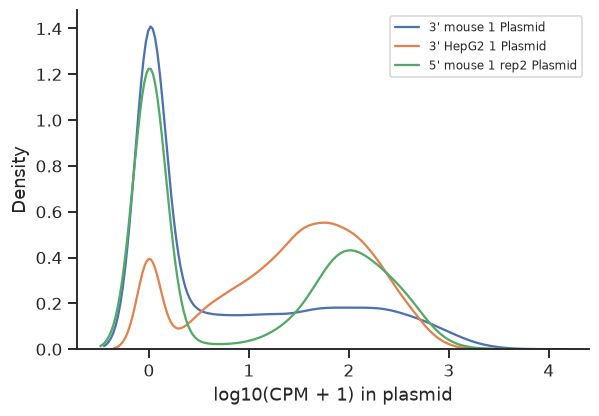

3' mouse 1 Plasmid: 20.5% of the sequences within 10x of the median
3' HepG2 1 Plasmid: 77.9% of the sequences within 10x of the median
5' mouse 1 rep2 Plasmid: 5.2% of the sequences within 10x of the median


In [13]:
cpm = counts / counts.sum() * 1e6

fig, ax = plt.subplots(figsize=(6, 4))
for s in ["3' mouse 1 Plasmid", "3' HepG2 1 Plasmid", "5' mouse 1 rep2 Plasmid"]:
    sns.kdeplot(np.log10(cpm[s] + 1), ax=ax, label=s)
ax.set_xlabel("log10(CPM + 1) in plasmid")
ax.legend(fontsize=8)
plt.show()

for s in ["3' mouse 1 Plasmid", "3' HepG2 1 Plasmid", "5' mouse 1 rep2 Plasmid"]:
    x = cpm[s]
    within = ((x > x.median() / 10) & (x < x.median() * 10)).mean() * 100
    print(f"{s}: {within:.1f}% of the sequences within 10x of the median")

In HepG2, most sequences are present within a 10-fold range of the median, which is typical for a good MPRA library. In the plasmid DNA recovered from the liver, the distribution is much broader, with many sequences at 0 (log10(1)): these were not delivered to (or not recovered from) the liver of this mouse. Again, this is the in vivo bottleneck.

### How similar are the samples?

We calculate the Pearson correlation between all samples on the log-transformed CPM values (`log2(CPM + 1)`), as in Extended Data Figure 6a of the paper.

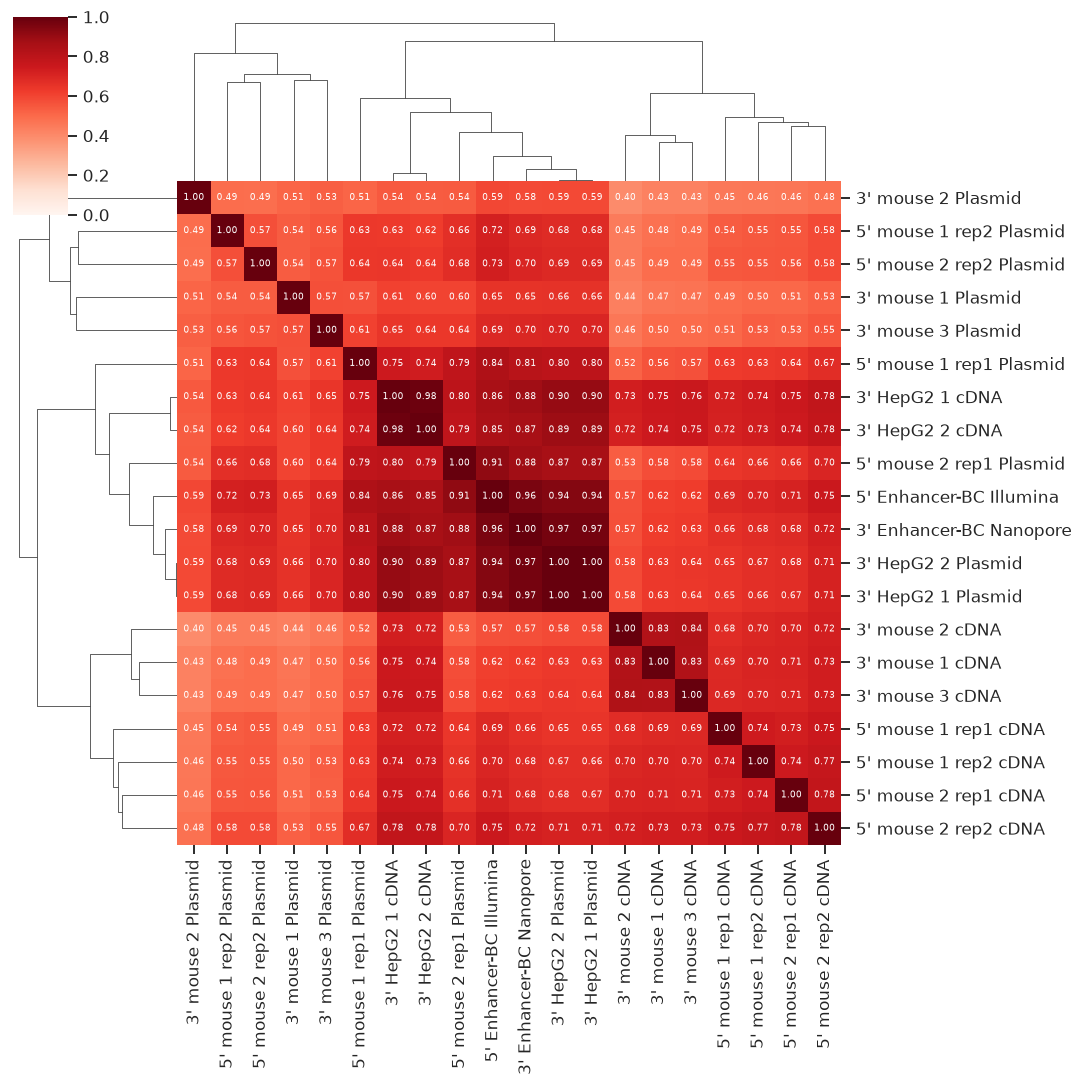

In [14]:
logcpm = np.log2(cpm + 1)
cor = logcpm.corr()
sns.clustermap(cor, cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6}, figsize=(10, 10))
plt.show()

- The plasmid samples are very similar to each other and to the assignment data: they all measure how abundant each sequence is in the plasmid library.
- The cDNA samples correlate less with the plasmid samples: the amount of RNA does not only depend on how much plasmid was delivered, but also on the **activity** of the enhancer. This is exactly what we want to measure.
- The cDNA samples of the same system cluster together, the 5' rep1 samples (with very few reads) are the most noisy.

### A first estimate of enhancer activity: the RNA/DNA ratio

The most intuitive way to measure the activity of an enhancer is the ratio of its barcode reads in the cDNA over its barcode reads in the plasmid (both normalized for sequencing depth). Let's compute this for two HepG2 replicates and see whether they agree.

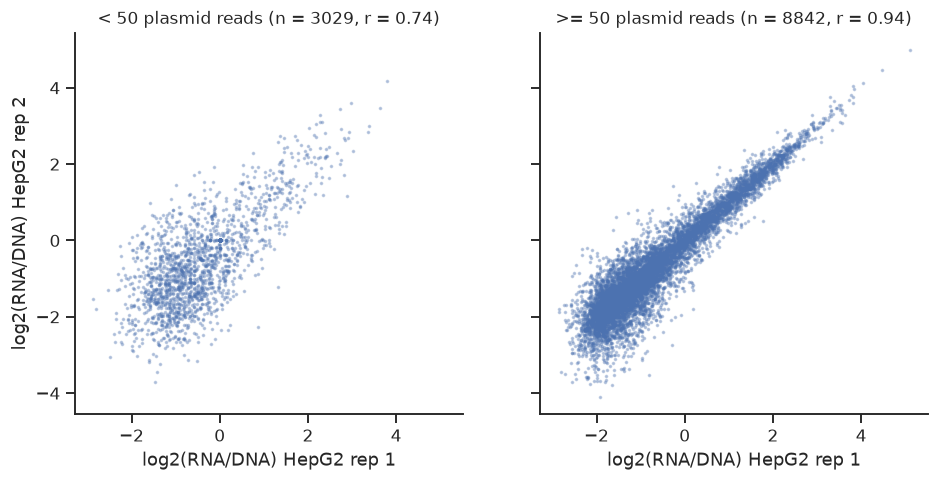

In [15]:
ratio1 = np.log2((cpm["3' HepG2 1 cDNA"] + 1) / (cpm["3' HepG2 1 Plasmid"] + 1))
ratio2 = np.log2((cpm["3' HepG2 2 cDNA"] + 1) / (cpm["3' HepG2 2 Plasmid"] + 1))
min_plasmid = counts[["3' HepG2 1 Plasmid", "3' HepG2 2 Plasmid"]].min(axis=1)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, sel, title in zip(axs, [min_plasmid < 50, min_plasmid >= 50], ["< 50 plasmid reads", ">= 50 plasmid reads"]):
    ax.scatter(ratio1[sel], ratio2[sel], s=2, alpha=0.3)
    r = pearsonr(ratio1[sel], ratio2[sel])[0]
    ax.set_title(f"{title} (n = {sel.sum()}, r = {r:.2f})")
    ax.set_xlabel("log2(RNA/DNA) HepG2 rep 1")
axs[0].set_ylabel("log2(RNA/DNA) HepG2 rep 2")
plt.show()

Sequences with few plasmid reads have a very noisy activity estimate. Replicates agree much better for well-represented sequences. Simply calculating a ratio ignores this: a ratio of 10 reads over 1 read is not as reliable as a ratio of 10,000 reads over 1,000 reads. A statistical model of count data, such as the one used by DESeq2, takes this into account.

## Step 3: modelling the barcode counts with DESeq2

In the RNA-seq practical we used DESeq2 to compare gene counts between two conditions. We can use exactly the same approach for MPRA data: we compare the barcode counts in the **cDNA** samples with the counts in the **plasmid** samples. The log2 fold change (cDNA vs plasmid) of a sequence is a measure of its activity, and DESeq2 takes care of:

- normalization for sequencing depth (size factors),
- the count noise and the variability between replicates (dispersion),
- *shrinking* unreliable estimates and *independent filtering* of sequences with too few reads (these get no adjusted p-value).

This is also the approach that the authors used. We write a small function, so that we can use it for all experiments in this notebook.

In [16]:
def mpra_deseq(count_table, cdna_samples, plasmid_samples):
    # DESeq2: cDNA vs plasmid, returns a table with one row per sequence
    samples = list(cdna_samples) + list(plasmid_samples)
    metadata = pd.DataFrame(
        {"condition": ["cDNA"] * len(cdna_samples) + ["Plasmid"] * len(plasmid_samples)},
        index=samples,
    )
    dds = DeseqDataSet(
        counts=count_table[samples].T,   # pydeseq2 expects samples as rows
        metadata=metadata,
        design="~condition",
        quiet=True,
    )
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "cDNA", "Plasmid"], quiet=True)
    stats.summary()
    return stats.results_df

**Mouse liver (in vivo)**: the authors combined the 3' (3 mice) and 5' (4 samples from 2 mice) experiments, so we have 7 cDNA and 7 plasmid samples. **HepG2**: 2 cDNA and 2 plasmid samples. This takes ~ 1 minute.

In [17]:
cdna_invivo    = coldata.index[(coldata.system == "mouse") & (coldata.type == "cDNA")]
plasmid_invivo = coldata.index[(coldata.system == "mouse") & (coldata.type == "Plasmid")]
cdna_hepg2     = coldata.index[(coldata.system == "HepG2") & (coldata.type == "cDNA")]
plasmid_hepg2  = coldata.index[(coldata.system == "HepG2") & (coldata.type == "Plasmid")]

res_invivo = mpra_deseq(counts, cdna_invivo, plasmid_invivo)
res_hepg2  = mpra_deseq(counts, cdna_hepg2, plasmid_hepg2)
res_invivo.head()

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287,275.762401,3.277327,1.179455,2.778680,0.005458,0.038200
chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458,62.658696,-0.948479,1.700996,-0.557602,0.577116,0.788513
chr1:102561276-102561534__mm10__AGCTCGTATGTT__chr1:102561214-102561715,317.918454,3.398804,1.095524,3.102446,0.001919,0.017836
chr1:102727483-102727741__mm10__TAGCGAGCCACA__chr1:102727338-102727839,618.618896,-1.743118,0.718185,-2.427115,0.015219,0.077254
chr1:102734119-102734377__mm10__GACCGTAGAACC__chr1:102733969-102734470,2.547065,4.784131,3.116898,1.534901,0.124808,NaN


The columns are the same as in the RNA-seq practical: `baseMean` (mean normalized count over all samples), `log2FoldChange` (cDNA vs plasmid), `lfcSE` (standard error of the log2 fold change), `stat`, `pvalue` and `padj`.

How many sequences got an adjusted p-value? Sequences with too few reads are removed by *independent filtering* (`padj` is `NaN`).

In [18]:
for name, res in [("in vivo", res_invivo), ("HepG2", res_hepg2)]:
    print(f"{name}: {res.shape[0]} sequences, {res['padj'].notna().sum()} with an adjusted p-value")

in vivo: 11871 sequences, 9284 with an adjusted p-value
HepG2: 11871 sequences, 10357 with an adjusted p-value


### MA plot

An MA plot shows the log2 fold change versus the mean count. We colour the shuffled sequences (negative controls) and the positive controls.

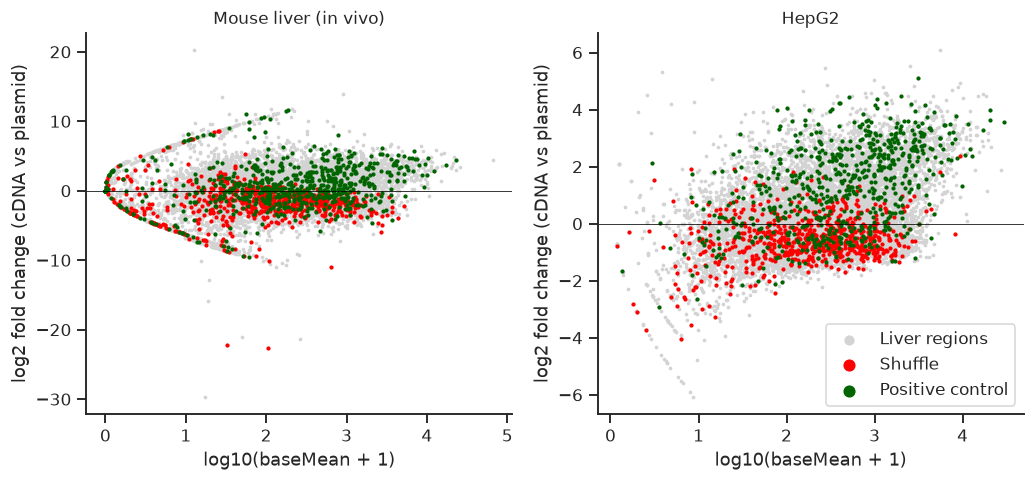

In [19]:
def ma_plot(res, title, ax):
    cls = ann["class"].reindex(res.index)
    ax.scatter(np.log10(res.baseMean + 1), res.log2FoldChange, s=2, c="lightgrey", label="Liver regions")
    for c, col in [("Shuffle", "red"), ("Positive control", "darkgreen")]:
        sel = cls == c
        ax.scatter(np.log10(res.baseMean[sel] + 1), res.log2FoldChange[sel], s=3, c=col, label=c)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_xlabel("log10(baseMean + 1)")
    ax.set_ylabel("log2 fold change (cDNA vs plasmid)")
    ax.set_title(title)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
ma_plot(res_invivo, "Mouse liver (in vivo)", axs[0])
ma_plot(res_hepg2, "HepG2", axs[1])
axs[1].legend(markerscale=4)
plt.show()

- Sequences with a low mean count have very variable log2 fold changes (the "funnel" on the left).
- Most shuffled sequences have a **negative** log2 fold change, most positive controls a high positive log2 fold change. This is a good sign: the assay can distinguish known active from inactive sequences.

**Question**: In RNA-seq, we test whether the log2 fold change is different from 0. Can we do the same here, i.e. call every sequence with `padj < 0.05` and `log2FoldChange > 0` an active enhancer? Think about what a log2 fold change of 0 means in an MPRA. (Hint: DESeq2 normalizes the samples assuming that *most* sequences have the same abundance in both conditions.)

## Step 4: which sequences are active enhancers?

The log2 fold change of 0 has no biological meaning in an MPRA: it depends on the normalization (DESeq2 centres the bulk of the library around 0), on the minimal promoter, the reporter gene, the amount of transfected plasmid... Instead, we compare each sequence to the **negative controls**: the 795 shuffled sequences. These have the same length and nucleotide composition as the liver regions, but their motifs are destroyed. Their activity reflects the background activity of the minimal promoter.

The authors fitted a **normal (Gaussian) distribution** to the log2 fold changes of the shuffled sequences, using the median and the median absolute deviation (MAD) as robust estimates of the mean and standard deviation (robust: insensitive to a few outliers). For each sequence they then calculate the probability of observing a log2 fold change at least this high under this background distribution (a one-sided p-value), correct for multiple testing (Benjamini-Hochberg) and call a sequence **active** if the adjusted p-value < 0.1.

In [20]:
def call_active(res, alpha=0.1):
    # only sequences with enough reads (that passed DESeq2's independent filtering)
    lfc = res.loc[res["padj"].notna(), "log2FoldChange"]
    shuffled = lfc[lfc.index.str.contains("__shuffle__")]
    loc = shuffled.median()
    scale = 1.4826 * (shuffled - loc).abs().median()   # MAD, scaled to be comparable with a standard deviation
    pval = norm.sf(lfc, loc=loc, scale=scale)            # P(X >= lfc) for X ~ N(loc, scale)
    padj = multipletests(pval, method="fdr_bh")[1]
    out = pd.DataFrame({"lfc": lfc, "pval": pval, "padj": padj, "active": padj < alpha})
    print(f"background (shuffled, n = {len(shuffled)}): median = {loc:.2f}, sd = {scale:.2f}")
    print(f"active: {out.active.sum()} of {len(out)} sequences ({out.active.mean() * 100:.1f}%)")
    return out, loc, scale

act_invivo, loc_invivo, sd_invivo = call_active(res_invivo)
act_hepg2, loc_hepg2, sd_hepg2 = call_active(res_hepg2)

background (shuffled, n = 570): median = -1.60, sd = 1.56
active: 2006 of 9284 sequences (21.6%)
background (shuffled, n = 674): median = -0.57, sd = 0.59
active: 3672 of 10357 sequences (35.5%)


Let's visualize this for the in vivo data: the distribution of the log2 fold changes of the shuffled sequences and the liver regions, the fitted normal distribution (black line), and the lowest log2 fold change that is called active (dashed line).

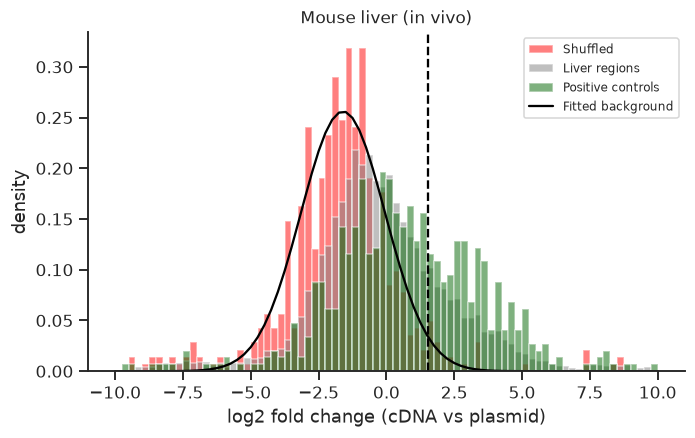

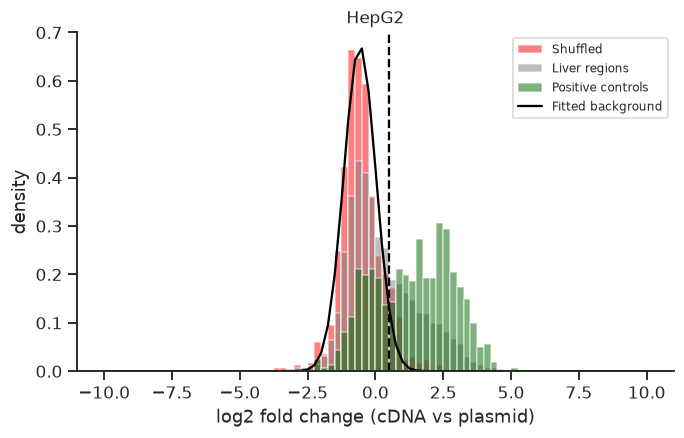

In [21]:
def plot_background(act, loc, scale, title):
    cls = ann["class"].reindex(act.index)
    fig, ax = plt.subplots(figsize=(7, 4))
    bins = np.linspace(-10, 10, 81)
    ax.hist(act.lfc[cls == "Shuffle"], bins=bins, density=True, alpha=0.5, color="red", label="Shuffled")
    ax.hist(act.lfc[~cls.isin(["Shuffle", "Positive control"])], bins=bins, density=True, alpha=0.5, color="grey", label="Liver regions")
    ax.hist(act.lfc[cls == "Positive control"], bins=bins, density=True, alpha=0.5, color="darkgreen", label="Positive controls")
    ax.plot(bins, norm.pdf(bins, loc, scale), color="black", label="Fitted background")
    ax.axvline(act.lfc[act.active].min(), ls="--", color="black")
    ax.set_xlabel("log2 fold change (cDNA vs plasmid)")
    ax.set_ylabel("density")
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.show()

plot_background(act_invivo, loc_invivo, sd_invivo, "Mouse liver (in vivo)")
plot_background(act_hepg2, loc_hepg2, sd_hepg2, "HepG2")

The fraction of active sequences per class:

In [22]:
summary = pd.DataFrame({
    "in vivo": act_invivo.active.groupby(ann["class"].reindex(act_invivo.index)).mean() * 100,
    "HepG2": act_hepg2.active.groupby(ann["class"].reindex(act_hepg2.index)).mean() * 100,
}).round(1)
summary.sort_values("in vivo", ascending=False)

,in vivo,HepG2
class,,
Positive control,37.0,69.0
Shared,25.4,47.2
General,21.7,29.1
Intermediate,14.0,23.5
Pericentral,13.3,20.4
Periportal,13.1,21.6
Shuffle,4.0,9.8


**Question**: 4% (in vivo) and 10% (HepG2) of the shuffled sequences are called active. Is that what you expect given how we defined the threshold? Would you expect 0%?

### Comparison with the results of the paper

The authors report 2,002 active sequences in vivo and 2,758 in HepG2 (columns `Invivo_24h_padj` and `HepG2_padj` in Supplementary Table 2). How well do our results agree?

In [23]:
for name, act, col in [("in vivo", act_invivo, "Invivo_24h"), ("HepG2", act_hepg2, "HepG2")]:
    both = act.join(ann[[col + "_LogFC", col + "_padj"]]).dropna()
    r = pearsonr(both["lfc"], both[col + "_LogFC"])[0]
    print(f"--- {name}: {len(both)} sequences in both analyses, correlation of log2FC: r = {r:.3f}")
    print(pd.crosstab(both["active"], both[col + "_padj"] < 0.1, rownames=["active (ours)"], colnames=["active (paper)"]))

--- in vivo: 7179 sequences in both analyses, correlation of log2FC: r = 0.999
active (paper)  False  True 
active (ours)               
False            5187    707
True                0   1285
--- HepG2: 10340 sequences in both analyses, correlation of log2FC: r = 0.918
active (paper)  False  True 
active (ours)               
False            6588     88
True              994   2670


The log2 fold changes are (almost) identical for the mouse data and very similar for HepG2. The number of active sequences is also very similar for the mouse data, but our analysis keeps more sequences: the authors removed some extra outliers and lowly covered sequences before calling active enhancers, so the background distribution and some of the calls differ. This is normal when re-analysing data: small differences in filtering change the details, not the conclusions. Below we continue with our own results.

We combine the in vivo and HepG2 results with the metadata in one table.

In [24]:
res12k = ann[["Genome", "Enhancer_type", "class", "annotation", "SYMBOL", "regulon", "Cloned_enhancer"]].join(
    act_invivo[["lfc", "active"]].rename(columns={"lfc": "lfc_invivo", "active": "active_invivo"})
).join(
    act_hepg2[["lfc", "active"]].rename(columns={"lfc": "lfc_hepg2", "active": "active_hepg2"})
)
res12k[["active_invivo", "active_hepg2"]] = res12k[["active_invivo", "active_hepg2"]].astype("boolean")  # True / False / NA (not tested)
res12k["region"] = np.where(res12k["annotation"].str.startswith("Promoter"), "Promoter", "Distal")
res12k.to_csv("12K_MPRA_activity.tsv", sep="\t")
res12k.head()

,Genome,Enhancer_type,class,annotation,SYMBOL,regulon,Cloned_enhancer,lfc_invivo,active_invivo,lfc_hepg2,active_hepg2,region
EnhancerID,,,,,,,,,,,,
chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287,mm10,Liver,Shared,Promoter (1-2kb),Arfgef1,"Nfib_+,Nfia_+",chr1:10142934-10143192,3.277327,True,2.076641,True,Promoter
chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458,mm10,Liver,Pericentral,Intron,Gm20268,NaN,chr1:102518082-102518340,-0.948479,False,-0.401312,False,Distal
chr1:102561276-102561534__mm10__AGCTCGTATGTT__chr1:102561214-102561715,mm10,Liver,Intermediate,Distal Intergenic,Gm20268,NaN,chr1:102561276-102561534,3.398804,True,0.638723,True,Distal
chr1:102727483-102727741__mm10__TAGCGAGCCACA__chr1:102727338-102727839,mm10,Liver,Pericentral,Distal Intergenic,Gm20268,NaN,chr1:102727483-102727741,-1.743118,False,-0.472245,False,Distal
chr1:102734119-102734377__mm10__GACCGTAGAACC__chr1:102733969-102734470,mm10,Liver,Intermediate,Distal Intergenic,Gm20268,NaN,chr1:102734119-102734377,NaN,<NA>,-1.069234,False,Distal


## Step 5: biological interpretation of the 12K library

### 5a. Are accessible regions active enhancers?

Let's compare the activity of the different classes of accessible regions with the shuffled sequences (Figure 3b of the paper). We use a one-sided Mann-Whitney U test (also called Wilcoxon rank-sum test) to test whether each class has higher log2 fold changes than the shuffled sequences, and correct the p-values for the number of tests (Bonferroni).

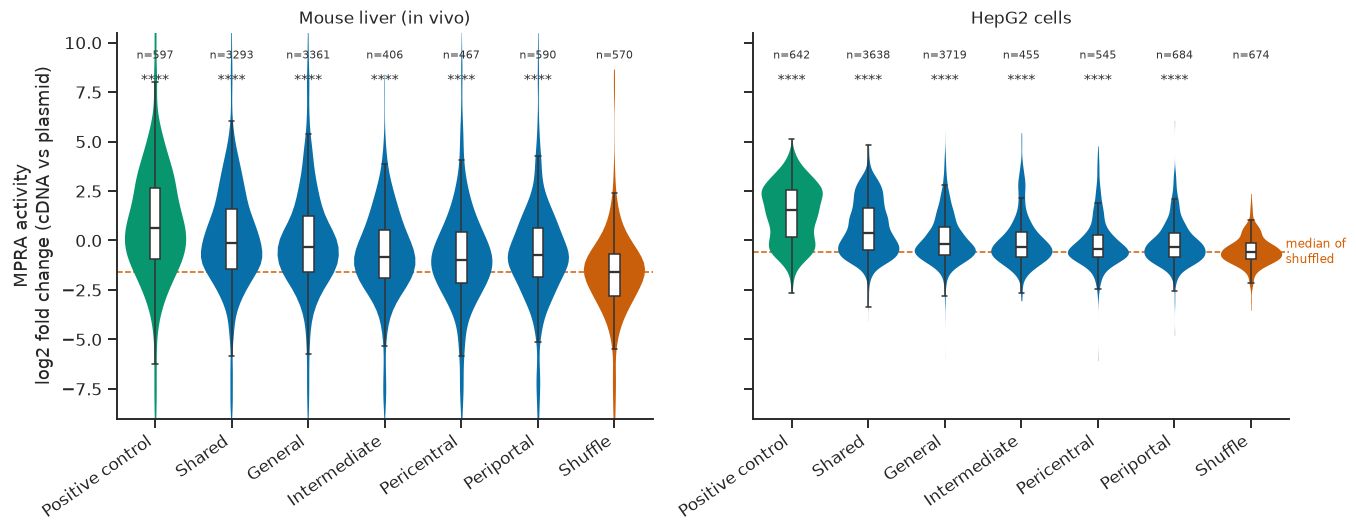

,system,class,n,median_lfc,pvalue,p_bonferroni
0,lfc_invivo,Positive control,597,0.654,0.0,0.0
1,lfc_invivo,Shared,3293,-0.127,0.0,0.0
2,lfc_invivo,General,3361,-0.348,0.0,0.0
3,lfc_invivo,Intermediate,406,-0.839,0.0,0.0
4,lfc_invivo,Pericentral,467,-0.968,0.0,0.0
5,lfc_invivo,Periportal,590,-0.748,0.0,0.0
6,lfc_invivo,Shuffle,570,-1.601,NaN,NaN
7,lfc_hepg2,Positive control,642,1.536,0.0,0.0
8,lfc_hepg2,Shared,3638,0.363,0.0,0.0
9,lfc_hepg2,General,3719,-0.177,0.0,0.0


In [25]:
order = ["Positive control", "Shared", "General", "Intermediate", "Pericentral", "Periportal", "Shuffle"]

def stars(p):
    return "****" if p <= 1e-4 else "***" if p <= 1e-3 else "**" if p <= 1e-2 else "*" if p <= 0.05 else "ns"

# one-sided Wilcoxon rank-sum test of each class against the shuffled sequences
tests = []
for col in ["lfc_invivo", "lfc_hepg2"]:
    shuf = res12k.loc[res12k["class"] == "Shuffle", col].dropna()
    for c in order:
        x = res12k.loc[res12k["class"] == c, col].dropna()
        p = np.nan if c == "Shuffle" else mannwhitneyu(x, shuf, alternative="greater").pvalue
        tests.append([col, c, len(x), x.median(), p])
tests = pd.DataFrame(tests, columns=["system", "class", "n", "median_lfc", "pvalue"])
tests["p_bonferroni"] = np.minimum(tests["pvalue"] * tests["pvalue"].notna().sum(), 1)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5), sharey=True)
for ax, col, title in zip(axs, ["lfc_invivo", "lfc_hepg2"], ["Mouse liver (in vivo)", "HepG2 cells"]):
    sns.violinplot(data=res12k, x="class", y=col, order=order, hue="class", palette=CLASS_COLORS,
                   cut=0, linewidth=0, saturation=.9, legend=False, ax=ax)
    sns.boxplot(data=res12k, x="class", y=col, order=order, width=.14, showfliers=False,
                boxprops=dict(facecolor="white", edgecolor=INK), whiskerprops=dict(color=INK),
                capprops=dict(color=INK), medianprops=dict(color=INK, lw=1.5), ax=ax)
    med_shuf = res12k.loc[res12k["class"] == "Shuffle", col].median()
    ax.axhline(med_shuf, color=VERM, lw=1, ls="--", zorder=0)
    sub = tests[tests.system == col].set_index("class")
    for i, c in enumerate(order):
        n, p = int(sub.loc[c, "n"]), sub.loc[c, "p_bonferroni"]
        ax.text(i, 9.2, f"n={n}", ha="center", fontsize=7, color=INK)
        if c != "Shuffle":
            ax.text(i, 7.9, stars(p), ha="center", fontsize=9, color=INK)
    ax.set(title=title, xlabel="", ylim=(-9, 10.5))
    ax.tick_params(axis="x", rotation=35)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")
axs[0].set_ylabel("MPRA activity\nlog2 fold change (cDNA vs plasmid)")
axs[1].set_ylabel("")
axs[1].text(6.4, med_shuf, " median of\n shuffled", color=VERM, fontsize=8, va="center")
plt.tight_layout()
plt.show()

tests.round(3)

- All classes of accessible regions are significantly more active than the shuffled sequences, both in the mouse liver and in HepG2.
- But the distributions overlap a lot: many accessible regions are not more active than a random sequence.

**Question**: Only 13 - 25% of the accessible regions are called active in vivo (20 - 47% in HepG2). Give some biological and technical reasons why an accessible region can be inactive in an MPRA. (Hint: think about what is different between the episomal plasmid and the genome, and about the size of the tested fragment.)

### 5b. Positive controls: human sequences in the mouse liver

The positive controls are human sequences that were active in HepG2 in previous studies (MPRA and STARR-seq), together with their mouse orthologs.

In [26]:
pc = res12k[res12k["class"] == "Positive control"].copy()
pc["species"] = np.where(pc["Genome"] == "hg19", "human (HepG2 controls)", "mouse ortholog")
pc.groupby("species")[["active_invivo", "active_hepg2"]].mean().mul(100).round(1)

,active_invivo,active_hepg2
species,,
human (HepG2 controls),39.1,74.7
mouse ortholog,34.9,63.2


**Question**: How do you explain these differences? Think about the species of the TFs present in the cells, and about how the positive controls were selected.

### 5c. Is enhancer activity in HepG2 the same as in the liver?

HepG2 cells are often used as a model for hepatocytes. Let's compare the activity of each sequence in both systems (Figure 3c).

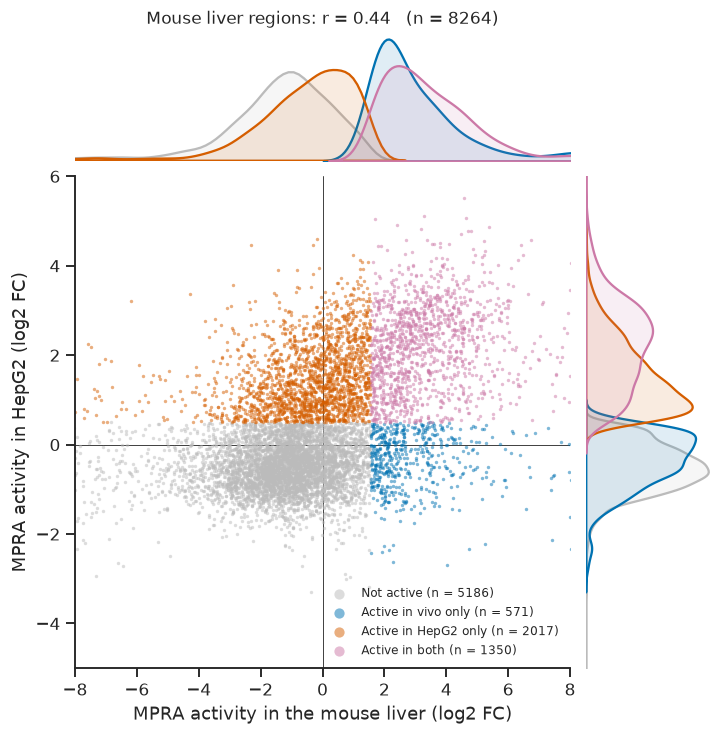

In [27]:
tested = res12k.dropna(subset=["lfc_invivo", "lfc_hepg2"]).copy()
tested["pattern"] = np.select(
    [tested.active_invivo.eq(True) & tested.active_hepg2.eq(True),
     tested.active_invivo.eq(True), tested.active_hepg2.eq(True)],
    ["Active in both", "Active in vivo only", "Active in HepG2 only"], default="Not active")
PATTERN_COLORS = {"Not active": GREY, "Active in vivo only": BLUE,
                  "Active in HepG2 only": VERM, "Active in both": PURPLE}

fig = plt.figure(figsize=(7.5, 7.5))
gs = fig.add_gridspec(2, 2, width_ratios=(5, 1.3), height_ratios=(1.3, 5),
                      wspace=.05, hspace=.05)
ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

for name in ["Not active", "Active in vivo only", "Active in HepG2 only", "Active in both"]:
    sub = tested[tested.pattern == name]
    ax.scatter(sub.lfc_invivo, sub.lfc_hepg2, s=5, alpha=.5, color=PATTERN_COLORS[name],
               label=f"{name} (n = {len(sub)})", linewidths=0)
    sns.kdeplot(x=sub.lfc_invivo, color=PATTERN_COLORS[name], ax=ax_top, lw=1.5, fill=True, alpha=.12)
    sns.kdeplot(y=sub.lfc_hepg2, color=PATTERN_COLORS[name], ax=ax_right, lw=1.5, fill=True, alpha=.12)

ax.axhline(0, color=INK, lw=.6, zorder=0)
ax.axvline(0, color=INK, lw=.6, zorder=0)
ax.set(xlabel="MPRA activity in the mouse liver (log2 FC)",
       ylabel="MPRA activity in HepG2 (log2 FC)", xlim=(-8, 8), ylim=(-5, 6))
ax.legend(markerscale=3, fontsize=8, loc="lower right", frameon=False)
for a in (ax_top, ax_right):
    a.set(xlabel="", ylabel="")
    a.tick_params(labelbottom=False, labelleft=False, bottom=False, left=False)
    a.spines[["left", "bottom"]].set_visible(False)
mm10 = tested[tested.Genome == "mm10"]
ax_top.set_title(f"Mouse liver regions: r = {pearsonr(mm10.lfc_invivo, mm10.lfc_hepg2)[0]:.2f}"
                 f"   (n = {len(mm10)})", fontsize=11)
plt.show()

The activity in HepG2 is only moderately correlated with the activity in the mouse liver. Let's classify the mouse liver regions (only those measured in both systems) as active in both systems, only in vivo, only in HepG2 or in none (Figure 3d), and check where in the genome they are located.

In [28]:
liver = tested[tested["Genome"] == "mm10"].copy()
pat_order = ["Not active", "Active in vivo only", "Active in both", "Active in HepG2 only"]
print(liver["pattern"].value_counts().reindex(pat_order).to_string())

prop = pd.crosstab(liver["pattern"], liver["region"], normalize="index").mul(100).loc[pat_order]
prop.round(1)

pattern
Not active              4625
Active in vivo only      551
Active in both          1234
Active in HepG2 only    1854


region,Distal,Promoter
pattern,,
Not active,69.0,31.0
Active in vivo only,75.5,24.5
Active in both,50.1,49.9
Active in HepG2 only,54.5,45.5


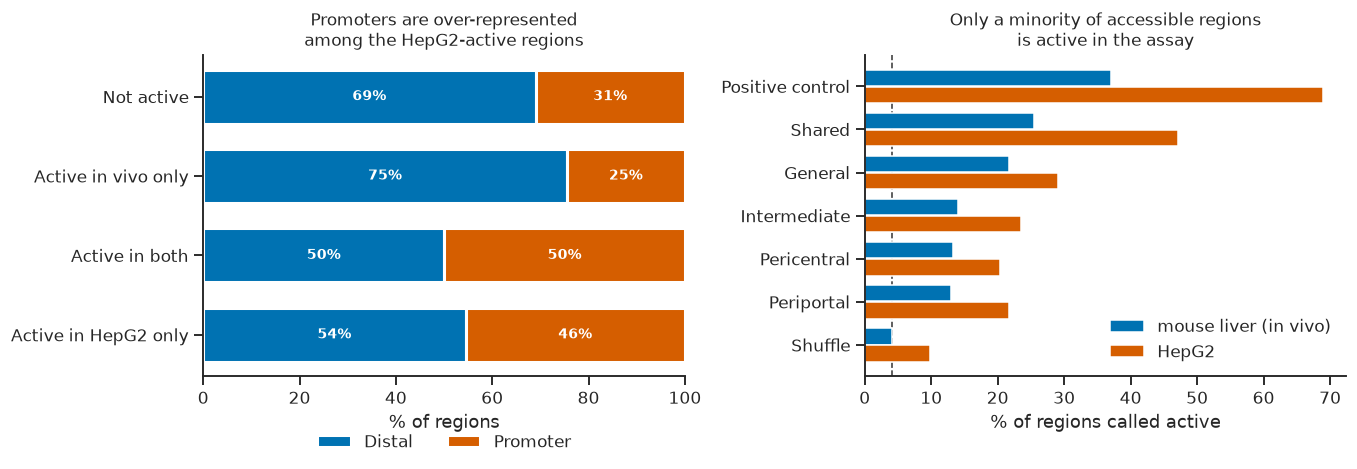

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))

# left: where in the genome do the regions of each activity class lie?
bottom = np.zeros(len(prop))
for region, color in [("Distal", BLUE), ("Promoter", VERM)]:
    axs[0].barh(prop.index, prop[region], left=bottom, color=color, height=.68,
                edgecolor="white", linewidth=2, label=region)
    for i, (v, b) in enumerate(zip(prop[region], bottom)):
        axs[0].text(b + v / 2, i, f"{v:.0f}%", ha="center", va="center",
                    color="white", fontsize=9, fontweight="bold")
    bottom += prop[region].values
axs[0].set(xlabel="% of regions", xlim=(0, 100), title="Promoters are over-represented\namong the HepG2-active regions")
axs[0].legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5, -.28))
axs[0].invert_yaxis()

# right: fraction of active regions per enhancer class, in both systems
cls_order = ["Positive control", "Shared", "General", "Intermediate", "Pericentral", "Periportal", "Shuffle"]
frac = pd.DataFrame({
    "in vivo": res12k.groupby("class").active_invivo.mean() * 100,
    "HepG2": res12k.groupby("class").active_hepg2.mean() * 100,
}).reindex(cls_order)
y = np.arange(len(frac))
axs[1].barh(y - .2, frac["in vivo"], height=.38, color=BLUE, label="mouse liver (in vivo)")
axs[1].barh(y + .2, frac["HepG2"], height=.38, color=VERM, label="HepG2")
axs[1].axvline(frac.loc["Shuffle", "in vivo"], color=INK, lw=1, ls="--", zorder=0)
axs[1].set_yticks(y, frac.index)
axs[1].set(xlabel="% of regions called active", title="Only a minority of accessible regions\nis active in the assay")
axs[1].legend(frameon=False, loc="lower right")
axs[1].invert_yaxis()
plt.tight_layout()
plt.show()

Regions that are only active in HepG2 are much more often **promoters**, while regions that are only active in the mouse liver are mostly **distal** (intronic and intergenic) regions. Promoters often contain motifs of ubiquitous TFs (e.g. ETS, NRF1, SP/KLF), which are also present in a cancer cell line. Distal enhancers depend more on cell-type specific TFs and their combinations.

**Question**: HepG2 cells are human cancer cells that have lost some hepatocyte features. Based on these results, would you use HepG2 cells to test mouse liver enhancers?

### 5d. Enhancer activity per eRegulon

SCENIC+ predicts which TFs regulate each region (`regulon` column). Let's look at the fraction of active regions for the targets of the main hepatocyte TFs (Figure 3e of the paper). Note that a region can be a target of several TFs.

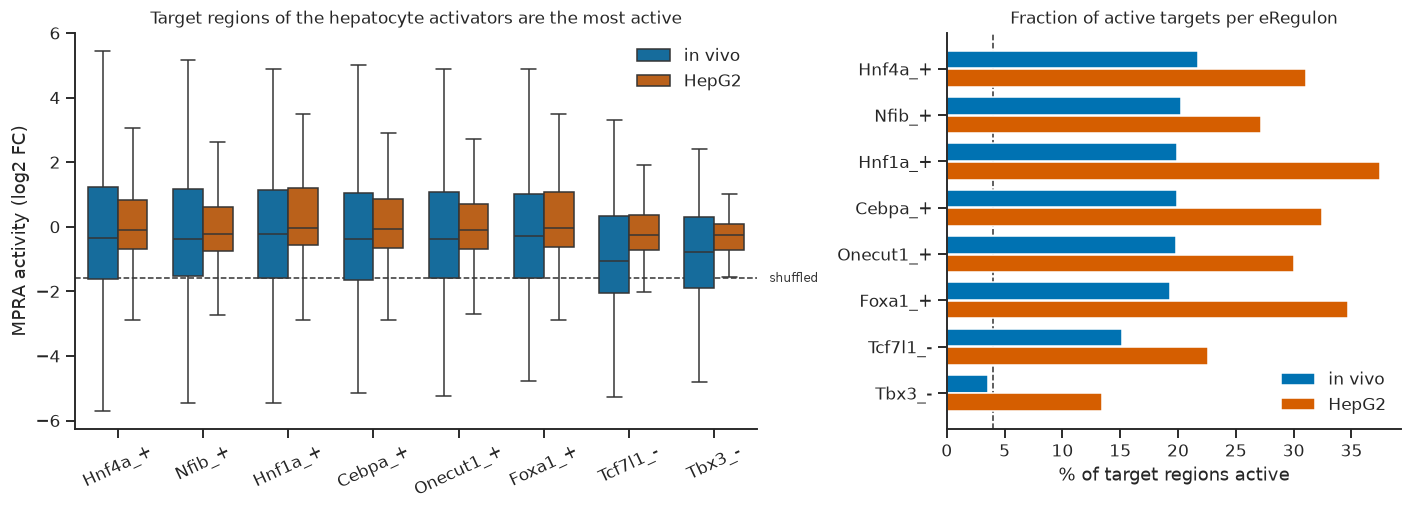

,n,median_lfc_invivo,pct_active_invivo,median_lfc_hepg2,pct_active_hepg2
regulon,,,,,
Hnf1a_+,264,-0.22,19.90,-0.03,37.44
Hnf4a_+,3546,-0.35,21.68,-0.11,31.02
Foxa1_+,438,-0.30,19.27,-0.05,34.74
Cebpa_+,666,-0.38,19.89,-0.08,32.42
Onecut1_+,517,-0.37,19.79,-0.10,30.05
Nfib_+,2124,-0.39,20.26,-0.23,27.17
Tcf7l1_-,163,-1.05,15.18,-0.26,22.56
Tbx3_-,77,-0.78,3.57,-0.26,13.43
Shuffle,795,-1.60,4.04,-0.57,9.79


In [30]:
regulons = ["Hnf1a_+", "Hnf4a_+", "Foxa1_+", "Cebpa_+", "Onecut1_+", "Nfib_+", "Tcf7l1_-", "Tbx3_-"]
rows, long = [], []
for reg in regulons:
    sel = res12k["regulon"].fillna("").str.contains(reg, regex=False)
    x = res12k[sel]
    rows.append([reg, int(sel.sum()), x.lfc_invivo.median(), x.active_invivo.mean() * 100,
                 x.lfc_hepg2.median(), x.active_hepg2.mean() * 100])
    long.append(pd.DataFrame({"regulon": reg, "lfc": x.lfc_invivo, "system": "in vivo"}))
    long.append(pd.DataFrame({"regulon": reg, "lfc": x.lfc_hepg2, "system": "HepG2"}))
shuf = res12k[res12k["class"] == "Shuffle"]
rows.append(["Shuffle", len(shuf), shuf.lfc_invivo.median(), shuf.active_invivo.mean() * 100,
             shuf.lfc_hepg2.median(), shuf.active_hepg2.mean() * 100])
summary = pd.DataFrame(rows, columns=["regulon", "n", "median_lfc_invivo", "pct_active_invivo",
                                      "median_lfc_hepg2", "pct_active_hepg2"]).set_index("regulon")
long = pd.concat(long).dropna()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=(1.5, 1)))
reg_order = summary.drop("Shuffle").sort_values("pct_active_invivo", ascending=False).index.tolist()
sns.boxplot(data=long, x="regulon", y="lfc", hue="system", order=reg_order,
            palette={"in vivo": BLUE, "HepG2": VERM}, showfliers=False, width=.7, ax=axs[0])
axs[0].axhline(shuf.lfc_invivo.median(), color=INK, ls="--", lw=1, zorder=0)
axs[0].text(7.6, shuf.lfc_invivo.median(), " shuffled", fontsize=8, color=INK, va="center")
axs[0].set(xlabel="", ylabel="MPRA activity (log2 FC)",
           title="Target regions of the hepatocyte activators are the most active")
axs[0].legend(frameon=False, title="")
axs[0].tick_params(axis="x", rotation=25)

y = np.arange(len(reg_order))
axs[1].barh(y - .2, summary.loc[reg_order, "pct_active_invivo"], height=.38, color=BLUE, label="in vivo")
axs[1].barh(y + .2, summary.loc[reg_order, "pct_active_hepg2"], height=.38, color=VERM, label="HepG2")
axs[1].axvline(summary.loc["Shuffle", "pct_active_invivo"], color=INK, ls="--", lw=1, zorder=0)
axs[1].set_yticks(y, reg_order)
axs[1].set(xlabel="% of target regions active", title="Fraction of active targets per eRegulon")
axs[1].legend(frameon=False, loc="lower right")
axs[1].invert_yaxis()
plt.tight_layout()
plt.show()

summary.round(2)

- The targets of all activator regulons (HNF1A, HNF4A, FOXA1, CEBPA, ONECUT1, NFIB) are much more often active than the shuffled sequences (~ 20% in vivo and ~ 30% in HepG2, versus 4% and 10%).
- The targets of the repressors TCF7L1 and especially TBX3 are less often active.

Note that the paper reports that TBX3 targets are *more* active in vivo than in HepG2 (20% vs 5%), while we find the opposite (only 77 TBX3 targets, 3.6% active in vivo). The paper uses a slightly different set of high-confidence regions and thresholds; with so few regions, such details can change the result.

**Question**: TBX3 is a repressor that is expressed in pericentral hepatocytes and its target regions are periportal enhancers. Would you expect these regions to be active in bulk liver? And in HepG2 cells (which express TBX3)?

### 5e. Which TF motifs make an accessible region active?

All tested regions are accessible in hepatocytes, so they are all (presumably) bound by hepatocyte TFs. Which motifs distinguish the **active** from the **inactive** regions? We use [HOMER](http://homer.ucsd.edu/homer/motif/) to test which known motifs are enriched in the active regions (target set) compared to the inactive regions (background set). We only use the mouse liver regions (not the controls).

First we write the coordinates of both sets to a BED file and extract their sequences from the mm10 genome with `bedtools getfasta`.

In [31]:
# The mouse genome sequence. On the VSC cluster a copy is available in the shared genome folder;
# otherwise download it once from UCSC (https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.fa.gz)
GENOME_FA = "/lustre1/project/res_00001/genomes/mus_musculus/mm10_ucsc/fasta/mm10.fa"
os.makedirs("homer", exist_ok=True)

def write_bed(regions, path):
    # "chr1:10142934-10143192" -> chr1  10142934  10143192
    regions.str.split("[:-]", regex=True, expand=True).to_csv(path, sep="\t", header=False, index=False)

liver_invivo = res12k[(res12k.Genome == "mm10") & res12k.active_invivo.notna()]
write_bed(liver_invivo.loc[liver_invivo.active_invivo, "Cloned_enhancer"], "homer/invivo_active.bed")
write_bed(liver_invivo.loc[~liver_invivo.active_invivo, "Cloned_enhancer"], "homer/invivo_inactive.bed")

In [32]:
!bedtools getfasta -fi {GENOME_FA} -bed homer/invivo_active.bed -fo homer/invivo_active.fa
!bedtools getfasta -fi {GENOME_FA} -bed homer/invivo_inactive.bed -fo homer/invivo_inactive.fa
!grep -c ">" homer/invivo_active.fa homer/invivo_inactive.fa
!head -n 2 homer/invivo_active.fa

homer/invivo_active.fa:1865


homer/invivo_inactive.fa:6547


>chr1:10142934-10143192
tataggaagctatgaactgccagacagggtgctagaaatgaaactgggtcttctgccaagaacagcaaatattcttaacctttgagctgtctctccagctccCACTTCCTAGTCAAATTACTAATTTACCATagaaaacagacagaaaaggctatggcaaacaagagcgtttcctggtgaaggcctgctcttttgcatgagactttgtcccaggactgcttctcattgcggatgtgtctttcctgctaccattacata


Now we run `findMotifs.pl` in FASTA mode (target and background are given as FASTA files). Options:

- `-fasta`: the background sequences
- `-nomotif`: only test known motifs (no *de novo* motif discovery, which takes much longer)
- `-mset vertebrates`: only use motifs of vertebrate TFs
- `-p 8`: use 8 threads

This takes ~ 30 seconds.

In [33]:
!findMotifs.pl homer/invivo_active.fa fasta homer/invivo_active_vs_inactive -fasta homer/invivo_inactive.fa -nomotif -mset vertebrates -p 8 > homer/invivo.log 2>&1

In [34]:
known = pd.read_csv("homer/invivo_active_vs_inactive/knownResults.txt", sep="\t")
known["Motif"] = known["Motif Name"].str.split("/").str[0]
known["pct_target"] = known["% of Target Sequences with Motif"].str.rstrip("%").astype(float)
known["pct_background"] = known["% of Background Sequences with Motif"].str.rstrip("%").astype(float)
known["enrichment"] = known["pct_target"] / known["pct_background"]
known["minus_log10_p"] = -known["Log P-value"] / np.log(10)
known["rank"] = np.arange(1, len(known) + 1)
cols = ["rank", "Motif", "minus_log10_p", "q-value (Benjamini)", "pct_target", "pct_background", "enrichment"]
known[cols].head(20).round(2)

,rank,Motif,minus_log10_p,q-value (Benjamini),pct_target,pct_background,enrichment
0,1,JunB(bZIP),33.97,0.0,15.82,6.21,2.55
1,2,Atf3(bZIP),32.09,0.0,17.16,7.33,2.34
2,3,Fra1(bZIP),31.73,0.0,15.23,6.08,2.50
3,4,Fos(bZIP),30.45,0.0,15.92,6.69,2.38
4,5,BATF(bZIP),30.16,0.0,16.73,7.28,2.30
5,6,Elk1(ETS),29.29,0.0,19.09,9.06,2.11
6,7,AP-1(bZIP),28.85,0.0,18.39,8.63,2.13
7,8,Elk4(ETS),28.74,0.0,19.09,9.15,2.09
8,9,Fosl2(bZIP),27.80,0.0,11.26,3.98,2.83
9,10,ELF1(ETS),27.68,0.0,18.18,8.63,2.11


A table of 1,000 motifs is hard to read. A **dot plot** shows three numbers at once: how strong the enrichment is (x), how significant it is (colour) and in how many regions the motif is found (size of the dot).

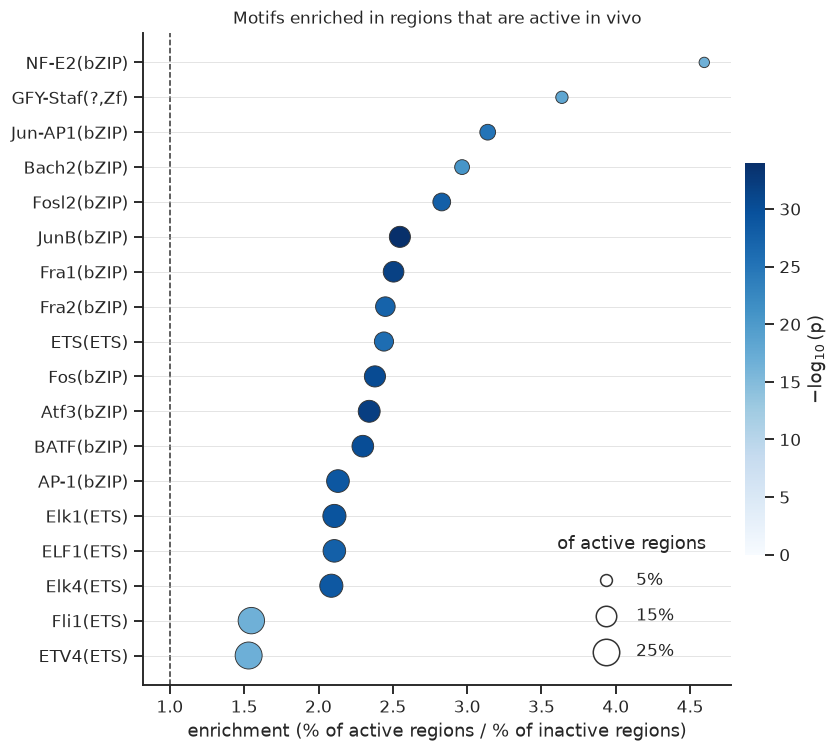

In [35]:
top = known.head(18).sort_values("enrichment")
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(top.enrichment, np.arange(len(top)), s=top.pct_target * 12,
                c=top.minus_log10_p, cmap="Blues", vmin=0, edgecolor=INK, linewidth=.6, zorder=3)
ax.axvline(1, color=INK, lw=1, ls="--", zorder=0)
ax.set_yticks(np.arange(len(top)), top.Motif)
ax.set(xlabel="enrichment (% of active regions / % of inactive regions)",
       title="Motifs enriched in regions that are active in vivo")
ax.grid(axis="y", color=GREY, lw=.5, alpha=.5, zorder=0)
cbar = fig.colorbar(sc, ax=ax, pad=.02, shrink=.6)
cbar.set_label("$-\\log_{10}$(p)")
cbar.outline.set_visible(False)
for pct in [5, 15, 25]:
    ax.scatter([], [], s=pct * 12, c="white", edgecolor=INK, label=f"{pct}%")
ax.legend(title="of active regions", frameon=False, loc="lower right", labelspacing=1.1, borderpad=1)
plt.tight_layout()
plt.show()

The most enriched motifs in active regions are **AP-1** (FOS/JUN/ATF3) and **ETS** (ELK1/4, ELF1). Where are the motifs of the hepatocyte TFs?

In [36]:
hep = known[known["Motif"].str.contains("HNF4|Hnf1|HNF1|FOXA|CEBP|HNF6|Onecut|Tbx3|Tcf7|TCFL2|LEF1", case=False)]
hep[cols].head(15).round(2)

,rank,Motif,minus_log10_p,q-value (Benjamini),pct_target,pct_background,enrichment
37,38,HNF1b(Homeobox),6.90,0.00,10.03,6.36,1.58
38,39,"HNF4a(NR),DR1",6.69,0.00,27.24,21.52,1.27
47,48,FOXA1(Forkhead),4.99,0.00,30.29,25.25,1.20
48,49,Hnf1(Homeobox),4.95,0.00,8.04,5.29,1.52
50,51,CEBP(bZIP),4.88,0.00,21.13,16.79,1.26
58,59,FOXA1(Forkhead),4.22,0.00,25.95,21.62,1.20
69,70,CEBP:CEBP(bZIP),3.24,0.00,2.47,1.31,1.89
78,79,Foxa2(Forkhead),2.64,0.01,22.95,19.86,1.16
97,98,Foxa3(Forkhead),1.81,0.07,11.37,9.61,1.18
102,103,CEBP:AP1(bZIP),1.71,0.09,17.16,15.13,1.13


The motifs of the hepatocyte activators HNF4A, FOXA, HNF1 and CEBP are also enriched in the active regions, but less strongly than ETS and AP-1. The motifs of the zonation repressors TBX3 and TCF7L1/2 (TCF/LEF) are not enriched.

This agrees with the paper: hepatocyte TFs (HNF4A, HNF1A, FOXA1, CEBPA, ONECUT1) determine *where* the chromatin is accessible in hepatocytes, so their motifs are present in most of the tested regions (active and inactive). On top of that, motifs of "activators" such as AP-1 and ETS (and promoter-like motifs) increase the activity of the accessible regions. The authors found the same features with a deep learning model trained on the MPRA data (Figure 4 of the paper).

**Exercise**: repeat the motif analysis for HepG2 (active vs inactive in HepG2). Which motifs do you expect to be most enriched?

## Step 6: the 455 library - changing enhancer activity by mutating TF binding sites

In the second experiment, the authors selected 41 enhancer windows (259 bp) from enhancers that are active in only one zone of the liver lobule: 25 **pericentral** (PC, around the central vein) and 16 **periportal** (PP, around the portal vein) windows. Using their deep learning model (DeepLiver), they introduced point mutations that destroy (**LOF**, loss of function) or create (**GOF**, gain of function) the binding sites of hepatocyte activators (HNF4A, HNF1A, CEBPA, FOXA1, ONECUT1) and of the zonation repressors TBX3 (pericentral) and TCF7L1/2 (periportal).

**Expectations**:

- GOF of an activator motif increases activity, LOF decreases activity.
- LOF of a repressor motif increases activity (in the zone where the repressor is expressed), GOF decreases activity.

Let's load the counts and the metadata (Supplementary Table 3).

In [37]:
bulk455 = pd.read_csv("geo/GSE218470_Bulk_455_MPRA_counts.tsv.gz", sep="\t", index_col=0)
ann455 = pd.read_excel(xlsx, sheet_name="Supplementary Table 3", header=1).set_index("Enhancer_name")
print(bulk455.shape, ann455.shape)
bulk455.columns.tolist()

(418, 18) (455, 34)


['Mouse_rep3S1_Plasmid',
 'Mouse_rep3S2_Plasmid',
 'Mouse_rep3S3_Plasmid',
 'Mouse_rep1S1_cDNA',
 'Mouse_rep1S2_cDNA',
 'Mouse_rep1S3_cDNA',
 'Mouse_rep1S4_cDNA',
 'Mouse_rep1S5_cDNA',
 'Mouse_rep2S1_cDNA',
 'Mouse_rep2S2_cDNA',
 'Mouse_rep2S3_cDNA',
 'HepG2_rep3S1_cDNA',
 'HepG2_rep3S1_Plasmid',
 'HepG2_rep3S2_cDNA',
 'HepG2_rep3S2_Plasmid',
 'HepG2_rep3S3_cDNA',
 'HepG2_rep3S3_Plasmid',
 'Nanopore_Assignments']

In [38]:
ann455[["region", "window", "pattern", "gene", "mutation_edited", "nmut"]].head(15)

,region,window,pattern,gene,mutation_edited,nmut
Enhancer_name,,,,,,
AldoB_HNF1A-GOF_A-C-268_CTRL_121_378_CAGCTACCTATT,AldoB,121_378,Mutation,AldoB,Hnf1a-GOF,1
AldoB_HNF1A-GOF_A-T-265_A-C-268_CTRL_121_378_AACGACCACATC,AldoB,121_378,Mutation,AldoB,Hnf1a-GOF,2
AldoB_HNF1A-GOF_A-T-265_CTRL_121_378_CTACACTTACAC,AldoB,121_378,Mutation,AldoB,Hnf1a-GOF,1
AldoB_HNF1A-LOF_A-C-263_CTRL_121_378_TAGAGAATCGCC,AldoB,121_378,Mutation,AldoB,Hnf1a-LOF,1
AldoB_HNF1A-LOF_A-T-259_A-C-263_CTRL_121_378_ATGCCACCAGGA,AldoB,121_378,Mutation,AldoB,Hnf1a-LOF,2
AldoB_HNF1A-LOF_A-T-259_CTRL_121_378_CAGTTCCAAGTT,AldoB,121_378,Mutation,AldoB,Hnf1a-LOF,1
AldoB_HNF4-GOF-HNF1A-GOF_G-A-214_T-C-217_T-A-225_A-T-265_A-C-268_CTRL_121_378_TTGCACCAGTTG,AldoB,121_378,Mutation,AldoB,Hnf4a-GOF_Hnf1a-GOF,0
AldoB_HNF4A-GOF_G-A-214_CTRL_121_378_AGGAGGAGAGGT,AldoB,121_378,Mutation,AldoB,Hnf4a-GOF,1
AldoB_HNF4A-GOF_G-A-214_T-C-217_T-A-225_CTRL_121_378_GCTTAGTCTTAC,AldoB,121_378,Mutation,AldoB,Hnf4a-GOF,3


The name of each sequence contains the enhancer region (or gene name for the controls), the mutation type, the exact nucleotide changes (e.g. `A-C-268`: the A at position 268 is mutated to a C), the zonation pattern of the original enhancer (`PC`, `PP` or `CTRL`), the window and the oligo barcode. The column `pattern` is `PC`, `PP` or `CTRL` for the wild-type (WT) sequences, `Mutation` for the variants and `Shuffle` for the negative controls.

We have 8 cDNA samples from mouse livers (48 h after injection) and 3 plasmid samples, and 3 cDNA and 3 plasmid samples from HepG2.

In [39]:
cdna_m   = [c for c in bulk455 if c.startswith("Mouse") and c.endswith("cDNA")]
plas_m   = [c for c in bulk455 if c.startswith("Mouse") and c.endswith("Plasmid")]
cdna_h   = [c for c in bulk455 if c.startswith("HepG2") and c.endswith("cDNA")]
plas_h   = [c for c in bulk455 if c.startswith("HepG2") and c.endswith("Plasmid")]

res455_mouse = mpra_deseq(bulk455, cdna_m, plas_m)
res455_hepg2 = mpra_deseq(bulk455, cdna_h, plas_h)

for name, res, col in [("mouse liver", res455_mouse, "Mouse48hr_LogFC"), ("HepG2", res455_hepg2, "HepG2_LogFC")]:
    both = res[["log2FoldChange"]].join(ann455[col]).dropna()
    print(f"{name}: correlation with the paper r = {pearsonr(both.iloc[:, 0], both.iloc[:, 1])[0]:.3f} (n = {len(both)})")

mouse liver: correlation with the paper r = 0.975 (n = 318)
HepG2: correlation with the paper r = 0.972 (n = 349)


### Effect of each mutation compared to the wild-type enhancer

Each variant has a matching wild-type (WT) sequence: the same region and the same window. For every variant we calculate the **change in activity** compared to its wild-type: Δlog2FC = log2FC(variant) − log2FC(WT). We only use variants in which one type of motif was mutated (e.g. `Hnf1a-GOF`, not `Hnf1a-GOF_Tcf7l1/2-LOF`).

In [40]:
var = ann455[["region", "window", "pattern", "gene", "mutation_edited"]].copy()
var["lfc_mouse"] = res455_mouse["log2FoldChange"]
var["lfc_hepg2"] = res455_hepg2["log2FoldChange"]
var["wt_key"] = var["region"].astype(str) + "_" + var["window"].astype(str)

# activity of the WT sequence of each region/window (mean if a WT sequence is present with more than one barcode)
wt = var[var["mutation_edited"] == "WT"].groupby("wt_key")[["lfc_mouse", "lfc_hepg2"]].mean()

single = var[(var["pattern"] == "Mutation") & ~var["mutation_edited"].str.contains("_")].copy()
single["delta_mouse"] = single["lfc_mouse"] - single["wt_key"].map(wt["lfc_mouse"])
single["delta_hepg2"] = single["lfc_hepg2"] - single["wt_key"].map(wt["lfc_hepg2"])
single["TF"] = single["mutation_edited"].str.rsplit("-", n=1).str[0]
single["direction"] = single["mutation_edited"].str.rsplit("-", n=1).str[1]
single = single[single["direction"].isin(["GOF", "LOF"])]
single.groupby(["TF", "direction"])[["delta_mouse", "delta_hepg2"]].agg(["median", "count"]).round(2)

delta_mouse       delta_hepg2      
                        median count      median count
TF       direction                                    
Cebpa    GOF              1.08     8        0.46     8
         LOF             -0.73     5       -1.41     5
Creb     GOF              0.49     1        0.42     1
Ets      GOF               NaN     0         NaN     0
         LOF             -0.06     4        0.07     4
Foxa1    GOF              0.58     6        0.70     6
         LOF             -0.76    11       -0.41    11
Hnf1a    GOF              1.75    27        1.18    27
         LOF             -3.63    12       -2.02    12
Hnf4a    GOF              0.63     8        1.37     8
         LOF             -1.64     9       -2.30     9
Onecut1  GOF             -0.61     3       -0.46     3
         LOF             -0.43     3       -0.30     3
Stat     LOF               NaN     0         NaN     0
Tbx3     GOF             -2.21     4       -0.21     5
         LOF              0.68     9        0.23     9
Tcf7l1/2 GOF             -0.28    17        0.46    17
         LOF             -0.34    41       -1.55    41
Thap     LOF              1.80     1        0.43     1

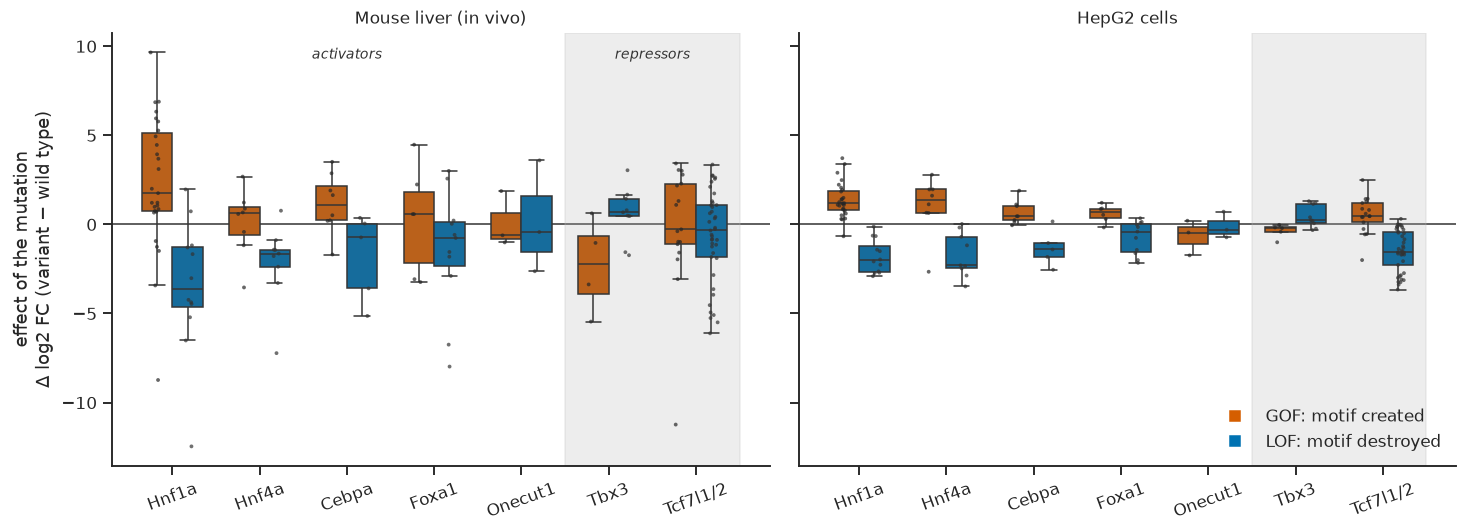

In [41]:
tfs = ["Hnf1a", "Hnf4a", "Cebpa", "Foxa1", "Onecut1", "Tbx3", "Tcf7l1/2"]
sub = single[single.TF.isin(tfs)]
fig, axs = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)
for ax, col, title in zip(axs, ["delta_mouse", "delta_hepg2"], ["Mouse liver (in vivo)", "HepG2 cells"]):
    sns.boxplot(data=sub, x="TF", y=col, hue="direction", order=tfs, hue_order=["GOF", "LOF"],
                palette={"GOF": VERM, "LOF": BLUE}, showfliers=False, width=.7, ax=ax)
    sns.stripplot(data=sub, x="TF", y=col, hue="direction", order=tfs, hue_order=["GOF", "LOF"],
                  dodge=True, color=INK, size=2.5, alpha=.7, legend=False, ax=ax)
    ax.axhline(0, color=INK, lw=1, zorder=0)
    ax.axvspan(4.5, 6.5, color=GREY, alpha=.25, zorder=0)       # the two repressors
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)
    ax.get_legend().remove()
axs[0].set_ylabel("effect of the mutation\nΔ log2 FC (variant − wild type)")
axs[0].text(5.5, 9.3, "repressors", ha="center", fontsize=9, color=INK, style="italic")
axs[0].text(2, 9.3, "activators", ha="center", fontsize=9, color=INK, style="italic")
handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=l)
           for l, c in [("GOF: motif created", VERM), ("LOF: motif destroyed", BLUE)]]
axs[1].legend(handles=handles, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In the mouse liver:

- **Activators**: creating HNF1A, HNF4A, CEBPA or FOXA1 sites (GOF) increases enhancer activity, destroying them (LOF) decreases activity. The effect of HNF1A is the strongest.
- **TBX3**: destroying TBX3 sites (LOF) *increases* activity and creating TBX3 sites (GOF) *decreases* activity. This is exactly what you expect for a **repressor**.
- **TCF7L1/2**: the effects are small in the bulk liver.

To see what this looks like for individual enhancers, we take four of the tested enhancers and plot every variant that was made of them, next to their wild-type sequence.

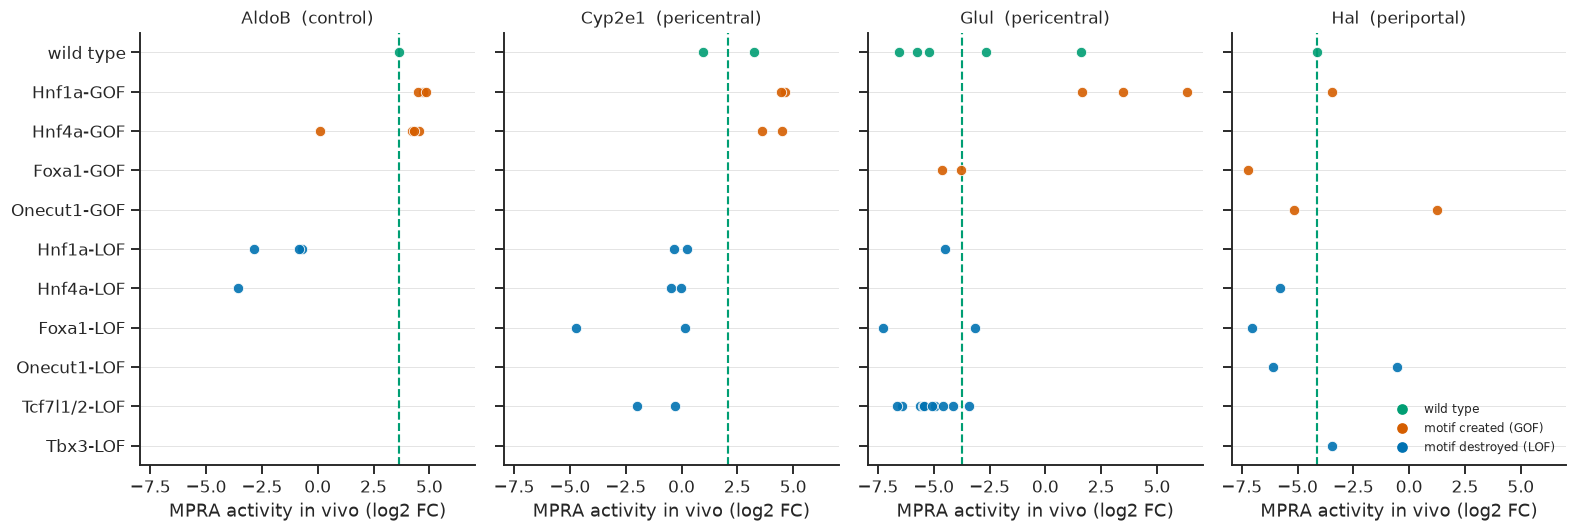

In [42]:
examples = [("AldoB", "control"), ("Cyp2e1", "pericentral"), ("Glul", "pericentral"), ("Hal", "periportal")]
rows = ["wild type", "Hnf1a-GOF", "Hnf4a-GOF", "Foxa1-GOF", "Onecut1-GOF",
        "Hnf1a-LOF", "Hnf4a-LOF", "Foxa1-LOF", "Onecut1-LOF", "Tcf7l1/2-LOF", "Tbx3-LOF"]
row_color = {r: (GREEN if r == "wild type" else VERM if r.endswith("GOF") else BLUE) for r in rows}

fig, axs = plt.subplots(1, 4, figsize=(14.5, 5), sharey=True, sharex=True)
for ax, (gene, zone) in zip(axs, examples):
    g = var[(var.gene == gene) & var.lfc_mouse.notna()].copy()
    g["label"] = np.where(g.mutation_edited == "WT", "wild type", g.mutation_edited)
    wt = g.loc[g.label == "wild type", "lfc_mouse"].mean()
    ax.axvline(wt, color=GREEN, ls="--", lw=1.4, zorder=1)
    for i, r in enumerate(rows):
        vals = g.loc[g.label == r, "lfc_mouse"]
        ax.scatter(vals, [i] * len(vals), color=row_color[r], s=46, alpha=.9,
                   zorder=3, edgecolor="white", linewidth=.6)
    ax.set(title=f"{gene}  ({zone})", xlabel="MPRA activity in vivo (log2 FC)")
    ax.grid(axis="y", color=GREY, lw=.5, alpha=.5, zorder=0)
axs[0].set_yticks(range(len(rows)), rows)
axs[0].invert_yaxis()
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l)
           for l, c in [("wild type", GREEN), ("motif created (GOF)", VERM), ("motif destroyed (LOF)", BLUE)]]
axs[3].legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

The dashed green line is the activity of the wild-type enhancer; a row is empty when that variant was not made for that enhancer.

- *AldoB* is the textbook case: it is a strong enhancer to begin with (log2FC = 3.6), adding HNF1A or HNF4A sites makes it stronger still, and destroying them costs it 4 to 7 log2 units, down to around the level of the negative controls.
- *Cyp2e1* behaves the same way, with a smaller starting activity.
- *Glul* is interesting: its wild-type window is **not** active in this assay, and destroying motifs changes nothing - you cannot switch off something that is already off. Adding HNF1A sites, however, turns it into an active enhancer (from -5.2 to +3.5).
- *Hal* shows the limits of the experiment: most of its variants exist in a single copy, and the values scatter over several log2 units without a clear pattern.

So single variants point in the expected direction most of the time, but the effect of a mutation *type* is only reliable when it is judged on many enhancers at once, as in the previous figure.

**Question**: Most of these effects are measured on only 5 - 30 sequences, and the variation is large. How could you improve the experimental design to measure the effect of a mutation more precisely?

**Question**: TCF7L1 is a repressor in periportal hepatocytes, TBX3 in pericentral hepatocytes. In the bulk liver, the cDNA comes from hepatocytes from all zones. Why does this make it difficult to see the effect of these repressors?

### Zonation: FACS-MPRA on pericentral and periportal hepatocytes

To measure activity in each zone, the authors injected the 455 library in 4 mice, isolated the hepatocytes and sorted them by FACS based on two surface markers:

- **CD73** (encoded by *Nt5e*): high in **pericentral** hepatocytes
- **E-cadherin** (ECAD, encoded by *Cdh1*): high in **periportal** hepatocytes

For each fraction (and two sub-fractions: high and low), the barcodes were sequenced from the cDNA. There are no plasmid samples for the sorted cells.

Let's load the counts. **Always look at your input files**: this file has a small problem.

In [43]:
!zcat geo/GSE218470_FACS_455_MPRA_counts.tsv.gz | head -n 2 | cat -A | cut -c 1-300

EcadHigh_S1_cDNA^IEcadHigh_S2_cDNA^IEcadHigh_S4_cDNA^IEcadLow_S1_cDNA^IEcadLow_S2_cDNA^IEcadLow_S3_cDNA^IEcadLow_S4_cDNA^ICD73_S1_cDNA^ICD73High_S2_cDNA^ICD73High_S4_cDNA^ICD73High_S3_cDNA^ICD73Low_S2_cDNA^ICD73Low_S3_cDNA^ICD73Low_S4_cDNA^INanopore_Assignments^I^M$
AldoB_HNF1A-GOF_A-C-268_CTRL_121_378_CAGCTACCTATT^I1392^I41865^I5206^I11874^I28055^I413^I3601^I4036^I146796^I2859^I666^I12412^I97894^I26897^I166^M$

gzip: stdout: Broken pipe


`cat -A` shows tabs as `^I`, line ends as `$` and Windows line endings as `^M`. Two things to notice:

- The header line ends with an extra tab (`^I^M$`), while the data lines do not. If we read this file with `index_col=0`, pandas would think that the first column name belongs to the index and all column names would be shifted by one!
- The lines end with `^M$` (Windows line endings, `\r\n`). Python and pandas handle these fine, but many command line tools (e.g. `awk`, `cut`) would keep the `\r` as part of the last field.

We therefore read the header ourselves.

In [44]:
fn = "geo/GSE218470_FACS_455_MPRA_counts.tsv.gz"
header = gzip.open(fn, "rt").readline().rstrip("\n").rstrip("\t").split("\t")
facs = pd.read_csv(fn, sep="\t", header=None, skiprows=1, index_col=0)
facs.columns = header
facs = facs.drop(columns="Nanopore_Assignments")
facs.sum()

EcadHigh_S1_cDNA     2061441
EcadHigh_S2_cDNA     2387615
EcadHigh_S4_cDNA    24262113
EcadLow_S1_cDNA      9609137
EcadLow_S2_cDNA      6888249
EcadLow_S3_cDNA     14514935
EcadLow_S4_cDNA     13452768
CD73_S1_cDNA        16456429
CD73High_S2_cDNA    22839003
CD73High_S4_cDNA    26070833
CD73High_S3_cDNA    12642868
CD73Low_S2_cDNA       399013
CD73Low_S3_cDNA     24560322
CD73Low_S4_cDNA     23297329
dtype: int64

The sample names contain the fraction (`EcadHigh`, `EcadLow`, `CD73`, `CD73High`, `CD73Low`) and the mouse (`S1` - `S4`). Note that not every fraction is available for every mouse. As in the paper, we sum the high and low sub-fractions per mouse, to get one ECAD (periportal) and one CD73 (pericentral) sample per mouse.

In [45]:
zon = {}
for mouse in ["S1", "S2", "S3", "S4"]:
    zon[f"Ecad_{mouse}"] = facs[[c for c in facs if c.startswith("Ecad") and f"_{mouse}_" in c]].sum(axis=1)
    zon[f"CD73_{mouse}"] = facs[[c for c in facs if c.startswith("CD73") and f"_{mouse}_" in c]].sum(axis=1)
zon = pd.DataFrame(zon)
zon.sum()

Ecad_S1    11670578
CD73_S1    16456429
Ecad_S2     9275864
CD73_S2    23238016
Ecad_S3    14514935
CD73_S3    37203190
Ecad_S4    37714881
CD73_S4    49368162
dtype: int64

There are no plasmid samples for the sorted cells. To still get an activity per fraction, the authors compared each fraction with the plasmid samples of the **bulk** in vivo experiment - the same library was injected, so its plasmid composition is a reasonable reference.

In [46]:
zon_with_plasmid = zon.join(bulk455[plas_m])
res455_Ecad = mpra_deseq(zon_with_plasmid, [c for c in zon if c.startswith("Ecad")], plas_m)
res455_CD73 = mpra_deseq(zon_with_plasmid, [c for c in zon if c.startswith("CD73")], plas_m)
var["lfc_Ecad"] = res455_Ecad["log2FoldChange"]
var["lfc_CD73"] = res455_CD73["log2FoldChange"]

for name, col, paper in [("ECAD (periportal)", "lfc_Ecad", "Ecad_LogFC"), ("CD73 (pericentral)", "lfc_CD73", "CD73_LogFC")]:
    both = var[[col]].join(ann455[paper]).dropna()
    print(f"{name}: correlation with the paper r = {pearsonr(both[col], both[paper])[0]:.3f} (n = {len(both)})")

ECAD (periportal): correlation with the paper r = 0.991 (n = 275)
CD73 (pericentral): correlation with the paper r = 0.990 (n = 279)


But borrowing the plasmid from another experiment is not ideal, and we are mainly interested in the *difference* between the zones anyway. Both fractions come from the **same mice**, so they received exactly the same plasmid. If we compare CD73 directly with ECAD within each mouse, the plasmid abundance cancels out. In DESeq2 we do this with a **paired design**: `~ mouse + fraction` (the same type of design you would use for samples before and after treatment of the same patients).

A positive log2 fold change (CD73 vs ECAD) means more activity in pericentral hepatocytes, a negative log2 fold change more activity in periportal hepatocytes.

In [47]:
meta_zon = pd.DataFrame(
    {"fraction": [c.split("_")[0] for c in zon], "mouse": [c.split("_")[1] for c in zon]},
    index=zon.columns,
)
dds_zon = DeseqDataSet(counts=zon.T, metadata=meta_zon, design="~mouse + fraction", quiet=True)
dds_zon.deseq2()
stats_zon = DeseqStats(dds_zon, contrast=["fraction", "CD73", "Ecad"], quiet=True)
stats_zon.summary()
res_zon = stats_zon.results_df
res_zon.head()

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,,,,,,
AldoB_HNF1A-GOF_A-C-268_CTRL_121_378_CAGCTACCTATT,59853.348106,-0.822840,1.542428,-0.533470,0.593708,0.776102
AldoB_HNF1A-GOF_A-T-265_A-C-268_CTRL_121_378_AACGACCACATC,283392.205437,-1.720555,1.596120,-1.077961,0.281051,0.555047
AldoB_HNF1A-GOF_A-T-265_CTRL_121_378_CTACACTTACAC,42838.126242,2.117711,1.610991,1.314539,0.188665,0.463204
AldoB_HNF1A-LOF_A-C-263_CTRL_121_378_TAGAGAATCGCC,18667.771552,3.922696,1.777973,2.206275,0.027365,0.154633
AldoB_HNF1A-LOF_A-T-259_A-C-263_CTRL_121_378_ATGCCACCAGGA,23228.425120,6.615442,1.766500,3.744943,0.000180,0.006308


Are sequences derived from pericentral enhancers (wild-type and variants) more active in pericentral hepatocytes than sequences derived from periportal enhancers?

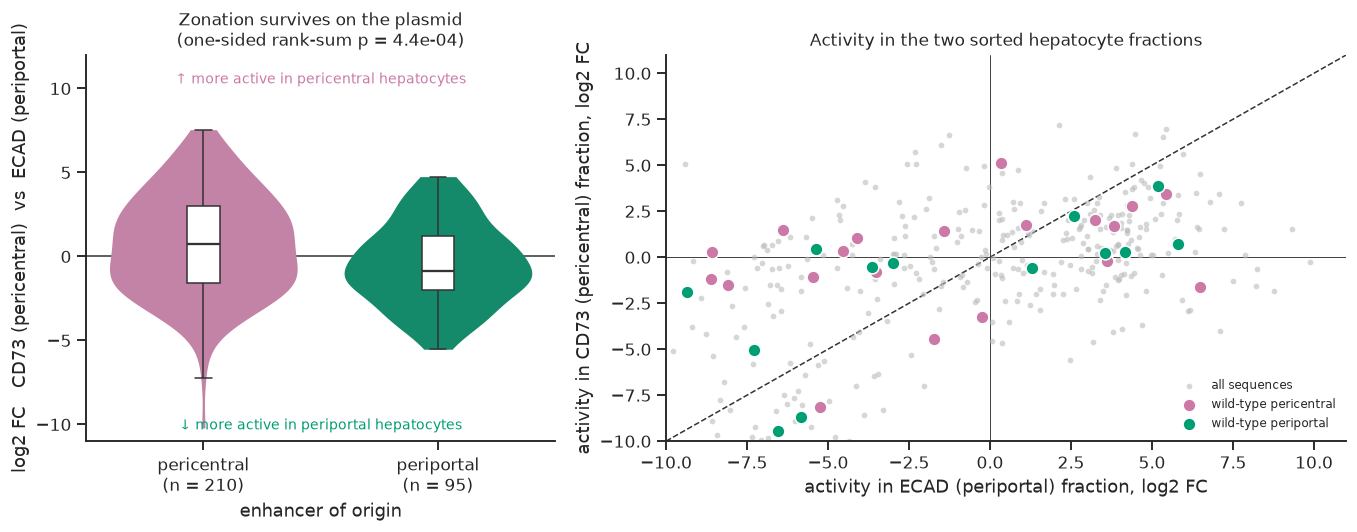

        median  count
origin               
PC        0.74    210
PP       -0.90     95


In [48]:
var["lfc_CD73_vs_Ecad"] = res_zon["log2FoldChange"]
origin = var[var["pattern"].isin(["PC", "PP"])].groupby("region")["pattern"].first()
var["origin"] = var["region"].map(origin)
ZON_COLORS = {"PC": PURPLE, "PP": GREEN}

x = var.dropna(subset=["origin", "lfc_CD73_vs_Ecad"])
pc = x.loc[x.origin == "PC", "lfc_CD73_vs_Ecad"]
pp = x.loc[x.origin == "PP", "lfc_CD73_vs_Ecad"]
pval = mannwhitneyu(pc, pp, alternative="greater").pvalue

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw=dict(width_ratios=(1, 1.45)))

# left: distribution of the zonation bias per enhancer of origin
sns.violinplot(data=x, x="origin", y="lfc_CD73_vs_Ecad", hue="origin", order=["PC", "PP"],
               palette=ZON_COLORS, cut=0, linewidth=0, legend=False, ax=axs[0])
sns.boxplot(data=x, x="origin", y="lfc_CD73_vs_Ecad", order=["PC", "PP"], width=.14, showfliers=False,
            boxprops=dict(facecolor="white", edgecolor=INK), whiskerprops=dict(color=INK),
            capprops=dict(color=INK), medianprops=dict(color=INK, lw=1.5), ax=axs[0])
axs[0].axhline(0, color=INK, lw=1, zorder=0)
axs[0].set_xticks([0, 1], [f"pericentral\n(n = {len(pc)})", f"periportal\n(n = {len(pp)})"])
axs[0].set(xlabel="enhancer of origin", ylim=(-11, 12),
           ylabel="log2 FC   CD73 (pericentral)  vs  ECAD (periportal)",
           title=f"Zonation survives on the plasmid\n(one-sided rank-sum p = {pval:.1e})")
axs[0].text(.5, 10.3, "↑ more active in pericentral hepatocytes", ha="center", color=PURPLE, fontsize=9)
axs[0].text(.5, -10.3, "↓ more active in periportal hepatocytes", ha="center", color=GREEN, fontsize=9)

# right: activity in the two sorted fractions, like Figure 8d of the paper
sc = var.dropna(subset=["lfc_Ecad", "lfc_CD73"])
axs[1].scatter(sc.lfc_Ecad, sc.lfc_CD73, s=14, color=GREY, alpha=.6, linewidths=0, label="all sequences")
for name, color, marker in [("PC", PURPLE, "o"), ("PP", GREEN, "o")]:
    w = sc[(sc.mutation_edited == "WT") & (sc.pattern == name)]
    axs[1].scatter(w.lfc_Ecad, w.lfc_CD73, s=70, color=color, marker=marker, edgecolor="white",
                   linewidth=1, zorder=3, label=f"wild-type {'pericentral' if name == 'PC' else 'periportal'}")
lims = (-10, 11)
axs[1].plot(lims, lims, color=INK, lw=1, ls="--", zorder=0)
axs[1].axhline(0, color=INK, lw=.6, zorder=0)
axs[1].axvline(0, color=INK, lw=.6, zorder=0)
axs[1].set(xlim=lims, ylim=lims, xlabel="activity in ECAD (periportal) fraction, log2 FC",
           ylabel="activity in CD73 (pericentral) fraction, log2 FC",
           title="Activity in the two sorted hepatocyte fractions")
axs[1].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

print(x.groupby("origin")["lfc_CD73_vs_Ecad"].agg(["median", "count"]).round(2).to_string())

Yes: sequences derived from pericentral enhancers have a higher activity in the pericentral (CD73) fraction than sequences derived from periportal enhancers. The **zonation** of these enhancers in the genome is (at least partly) encoded in their 259 bp sequence, and is reproduced on a plasmid.

How precise are these measurements? Some wild-type sequences were included with two different oligo barcodes: they are identical sequences, so they should give the same result.

In [49]:
dups = var[var["mutation_edited"] == "WT"].dropna(subset=["lfc_CD73_vs_Ecad"])
dups = dups[dups.duplicated("wt_key", keep=False)].sort_values("wt_key")
dups[["wt_key", "pattern", "lfc_mouse", "lfc_CD73_vs_Ecad"]]

,wt_key,pattern,lfc_mouse,lfc_CD73_vs_Ecad
Enhancer_name,,,,
chr1:153770263-153770763_WT_PC_120_377_ATAGCTCATCGT,chr1:153770263-153770763_120_377,PC,1.594707,-2.222730
chr1:153770263-153770763_WT_PC_120_377_CCAGACAGTGCT,chr1:153770263-153770763_120_377,PC,-2.645170,5.423246


The same sequence can give very different results in the sorted cells. Only 100,000 - 200,000 hepatocytes were sorted per fraction and the barcodes were amplified with many PCR cycles (24 + 10). With so few cells, each enhancer is only present in a small number of cells (and with a small number of barcodes), so the counts are dominated by sampling noise (a *bottleneck*). This is why the effects of individual variants are hard to measure in the FACS-MPRA, and why the paper combines many variants per mutation type (Figure 8c).

**Question**: The authors conclude that destroying TBX3 sites increases the activity of periportal enhancers in pericentral hepatocytes. Calculate Δ(log2FC CD73 vs ECAD) between the `Tbx3-LOF` variants and their wild-type sequences, as we did above for the bulk data. Do you find the same? How confident are you in this result?

## Conclusions

- An MPRA measures the activity of thousands of sequences in parallel by counting barcodes in RNA (cDNA) and DNA (plasmid). DESeq2 can be used to model these counts, and shuffled sequences provide the background to decide which sequences are active.
- Being accessible is not enough to be an active enhancer: only 13 - 25% of the hepatocyte accessible regions are active in vivo, but every class is significantly more active than random sequences.
- Activity in a cell line (HepG2) only partly reflects activity in the liver: HepG2 favours promoter-like sequences, while many distal enhancers are only active in vivo.
- Motifs of hepatocyte TFs (HNF4A, HNF1A, FOXA, CEBP) are present in most accessible regions; additional motifs (AP-1, ETS) distinguish active from inactive regions.
- Mutating TF binding sites changes enhancer activity as predicted: GOF of activator motifs increases activity, and destroying TBX3 sites (a repressor) increases activity.
- Zonation is (partly) encoded in the enhancer sequence: pericentral-derived sequences are more active in pericentral hepatocytes. However, measuring zonation effects of individual variants is limited by the low number of sorted cells.

**Exercise**: the 12K library was also tested in AML12 cells, a mouse hepatocyte cell line (GEO: [GSE236121](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE236121)). Download `GSE236121_AML12_MPRA_counts.tsv.gz`, call active enhancers and compare with HepG2 and the mouse liver. Is a *mouse* cell line a better model for the mouse liver than HepG2?